### Analisis perubahan harga (Price Change Analysis)

In [11]:
# MoM (Month-over-Month)
import numpy as np
import pandas as pd
from pathlib import Path

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)

DATA_PATH = Path("../data/processed/harga_10_komoditas.csv")
MIN_HARI_BULAN = 15   # bulan dianggap valid kalau minimal 15 hari berisi harga

assert DATA_PATH.exists(), f"File tidak ditemukan: {DATA_PATH.resolve()}"

data = pd.read_csv(DATA_PATH, parse_dates=["tanggal"])
data["anomali"] = data["anomali"].astype(bool)
data["bulan"] = data["tanggal"].dt.to_period("M")

# Data dasar untuk semua statistik: hari anomali tidak ikut dihitung
dasar = data[~data["anomali"]]

# Harga rata-rata bulanan per komoditas (hari anomali tidak ikut dihitung)
agg = (
    dasar
    .groupby(["komoditas", "bulan"])["harga"]
    .agg(harga_rata2="mean", hari_data="size")
    .reset_index()
)
agg.loc[agg["hari_data"] < MIN_HARI_BULAN, "harga_rata2"] = np.nan

rata = agg.pivot(index="bulan", columns="komoditas", values="harga_rata2")
rata = rata.reindex(pd.period_range(rata.index.min(), rata.index.max(), freq="M"))
rata.index.name = "bulan"


def ubah(p_t, p_ref):
    """Perubahan (%) = (P_t - P_ref) / P_ref x 100"""
    return (p_t - p_ref) / p_ref * 100


def panjang(wide, nama):
    return wide.reset_index().melt(id_vars="bulan", var_name="komoditas", value_name=nama)


# MoM: bulan ini vs bulan lalu
mom = ubah(rata, rata.shift(1))

perubahan = (
    panjang(rata, "harga_rata2")
    .merge(panjang(mom, "mom_pct"), on=["komoditas", "bulan"])
    .sort_values(["komoditas", "bulan"])
    .reset_index(drop=True)
)

# Hapus bulan pertama karena tidak memiliki pembanding
perubahan = perubahan[perubahan["bulan"] > perubahan["bulan"].min()].reset_index(drop=True)
perubahan[["harga_rata2", "mom_pct"]] = perubahan[["harga_rata2", "mom_pct"]].round(2)

print(f"Baris: {len(perubahan):,} | Komoditas: {perubahan['komoditas'].nunique()}")
print(f"Periode: {perubahan['bulan'].min()} s.d. {perubahan['bulan'].max()}")

# MoM seluruh periode (baris = bulan, kolom = komoditas)
perubahan.pivot(index="bulan", columns="komoditas", values="mom_pct")

Baris: 430 | Komoditas: 10
Periode: 2023-02 s.d. 2026-08


komoditas,Bawang Bombay,Bayam (Jenis Sayur),Buncis,Kacang Kedelai (Kualitas Lokal),Kangkung (Jenis Panjang),Kubis,Sawi (Jenis Hijau),Terong Ungu (Jenis Sayur),Tomat,Wortel (Kualitas Lokal)
bulan,,,,,,,,,,
2023-02,-1.49,8.11,2.46,1.32,1.33,-13.21,3.59,-4.45,-5.24,-6.53
2023-03,8.27,7.31,7.81,6.61,9.88,-9.43,1.40,-3.85,10.67,-0.36
2023-04,47.79,-0.65,8.45,3.14,-0.13,-0.04,2.65,3.18,26.70,3.69
2023-05,19.64,0.88,11.11,-2.30,1.01,-4.10,0.00,1.29,-6.53,0.06
2023-06,-7.06,-2.61,-4.21,0.00,-0.67,-4.88,-2.92,0.53,-10.17,-0.66
2023-07,-20.16,-14.03,-11.65,-6.64,-13.13,1.49,-9.87,-5.58,-31.94,2.09
2023-08,-6.40,0.89,-17.92,-1.83,5.63,-6.88,13.36,3.82,-3.08,2.25
2023-09,-3.97,1.91,11.49,0.94,-1.42,0.98,0.11,-7.16,-6.73,7.22
2023-10,-1.36,2.36,4.08,6.25,0.16,1.03,11.80,0.01,-8.19,2.08


In [12]:
# YtD (Year-to-Date)
# YtD: bulan ini vs Januari tahun berjalan
januari = rata[rata.index.month == 1].copy()
januari.index = januari.index.year

# Rata-rata Januari dipetakan ke setiap bulan pada tahun yang sama
ref_jan = pd.DataFrame(
    januari.reindex(rata.index.year).to_numpy(),
    index=rata.index,
    columns=rata.columns,
)

ytd = ubah(rata, ref_jan)

perubahan = perubahan.merge(panjang(ytd, "ytd_pct"), on=["komoditas", "bulan"], how="left")
perubahan["ytd_pct"] = perubahan["ytd_pct"].round(2)

print(f"Baris: {len(perubahan):,} | Kolom: {list(perubahan.columns)}")

# YtD seluruh periode (baris = bulan, kolom = komoditas)
perubahan.pivot(index="bulan", columns="komoditas", values="ytd_pct")

Baris: 430 | Kolom: ['bulan', 'komoditas', 'harga_rata2', 'mom_pct', 'ytd_pct']


komoditas,Bawang Bombay,Bayam (Jenis Sayur),Buncis,Kacang Kedelai (Kualitas Lokal),Kangkung (Jenis Panjang),Kubis,Sawi (Jenis Hijau),Terong Ungu (Jenis Sayur),Tomat,Wortel (Kualitas Lokal)
bulan,,,,,,,,,,
2023-02,-1.49,8.11,2.46,1.32,1.33,-13.21,3.59,-4.45,-5.24,-6.53
2023-03,6.65,16.02,10.47,8.01,11.34,-21.39,5.04,-8.13,4.87,-6.86
2023-04,57.62,15.27,19.80,11.40,11.20,-21.43,7.83,-5.21,32.87,-3.43
2023-05,88.57,16.28,33.11,8.84,12.32,-24.65,7.83,-3.98,24.19,-3.37
2023-06,75.26,13.24,27.51,8.84,11.57,-28.33,4.68,-3.47,11.56,-4.01
2023-07,39.92,-2.64,12.65,1.61,-3.08,-27.26,-5.65,-8.85,-24.07,-2.01
2023-08,30.97,-1.78,-7.53,-0.25,2.38,-32.26,6.96,-5.37,-26.41,0.20
2023-09,25.77,0.10,3.09,0.69,0.93,-31.60,7.08,-12.15,-31.36,7.44
2023-10,24.06,2.46,7.30,6.98,1.09,-30.89,19.71,-12.14,-36.98,9.67


In [13]:
# YoY (Year-over-Year)
# YoY: bulan ini vs bulan yang sama tahun lalu
yoy = ubah(rata, rata.shift(12))

perubahan = perubahan.merge(panjang(yoy, "yoy_pct"), on=["komoditas", "bulan"], how="left")
perubahan["yoy_pct"] = perubahan["yoy_pct"].round(2)

# Simpan hasil analisis perubahan harga (seluruh periode)
Path("../reports/tables").mkdir(parents=True, exist_ok=True)
perubahan.to_csv("../reports/tables/perubahan_harga.csv", index=False)

# Tabel YoY khusus mulai Januari 2024
AWAL_YOY = pd.Period("2024-01", freq="M")
yoy_tabel = (
    perubahan.loc[perubahan["bulan"] >= AWAL_YOY, ["bulan", "komoditas", "harga_rata2", "yoy_pct"]]
    .reset_index(drop=True)
)
yoy_tabel.to_csv("../reports/tables/perubahan_harga_yoy.csv", index=False)

print(f"Baris perubahan: {len(perubahan):,} | Baris YoY: {len(yoy_tabel):,}")
print(f"Periode YoY: {yoy_tabel['bulan'].min()} s.d. {yoy_tabel['bulan'].max()}")
print(f"NaN pada YoY: {int(yoy_tabel['yoy_pct'].isna().sum())}")

# YoY mulai 2024 (baris = bulan, kolom = komoditas)
yoy_tabel.pivot(index="bulan", columns="komoditas", values="yoy_pct")

Baris perubahan: 430 | Baris YoY: 320
Periode YoY: 2024-01 s.d. 2026-08
NaN pada YoY: 0


komoditas,Bawang Bombay,Bayam (Jenis Sayur),Buncis,Kacang Kedelai (Kualitas Lokal),Kangkung (Jenis Panjang),Kubis,Sawi (Jenis Hijau),Terong Ungu (Jenis Sayur),Tomat,Wortel (Kualitas Lokal)
bulan,,,,,,,,,,
2024-01,22.56,4.42,14.67,9.19,-2.80,-21.82,16.81,-13.11,28.07,10.84
2024-02,27.88,-0.63,1.18,7.93,-1.22,-13.86,12.76,-8.78,54.88,23.04
2024-03,25.87,-6.62,39.52,1.84,-9.21,-7.02,11.20,-2.47,56.66,20.69
2024-04,-10.26,-6.02,19.98,-1.72,-9.96,4.39,8.33,-1.59,62.01,18.05
2024-05,-1.87,-4.85,0.40,6.87,-15.46,33.96,19.89,0.66,34.05,17.44
2024-06,4.46,-1.79,-1.18,9.46,-14.60,44.66,20.17,0.16,-2.24,15.76
2024-07,19.32,10.22,-6.62,17.95,-1.31,12.75,22.58,2.17,-12.15,13.99
2024-08,15.11,5.60,9.31,21.94,-5.69,3.55,0.81,-6.08,-26.90,-4.13
2024-09,19.00,-1.52,3.54,23.26,-5.22,6.42,0.70,-1.49,-22.47,-15.27


### Analisis statistik dan fluktuasi harga (Price Statistics & Volatility)

In [14]:
# CV (coefficient of variation) per komoditas per bulan, seluruh periode (hari anomali tidak ikut dihitung)
# Statistik harga per komoditas per bulan, seluruh periode (hari anomali tidak ikut dihitung)
statistik_bulanan = (
    dasar.groupby(["komoditas", "bulan"])["harga"]
    .agg(
        hari_data="size",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max",
        std="std",
    )
    .reset_index()
)

statistik_bulanan["range"] = statistik_bulanan["maximum"] - statistik_bulanan["minimum"]
statistik_bulanan["cv_pct"] = statistik_bulanan["std"] / statistik_bulanan["mean"] * 100
statistik_bulanan["bulan_valid"] = statistik_bulanan["hari_data"] >= MIN_HARI_BULAN

kolom_harga = ["mean", "median", "minimum", "maximum", "range", "std"]
statistik_bulanan[kolom_harga] = statistik_bulanan[kolom_harga].round(0)
statistik_bulanan["cv_pct"] = statistik_bulanan["cv_pct"].round(2)

statistik_bulanan = statistik_bulanan[
    ["bulan", "komoditas", "hari_data", "bulan_valid", "mean", "median",
     "minimum", "maximum", "range", "std", "cv_pct"]
].sort_values(["komoditas", "bulan"]).reset_index(drop=True)

Path("../reports/tables").mkdir(parents=True, exist_ok=True)
statistik_bulanan.to_csv("../reports/tables/statistik_harga_bulanan.csv", index=False)

print(f"Baris: {len(statistik_bulanan):,} | Komoditas: {statistik_bulanan['komoditas'].nunique()}")
print(f"Periode: {statistik_bulanan['bulan'].min()} s.d. {statistik_bulanan['bulan'].max()}")
print(f"Bulan tidak valid (< {MIN_HARI_BULAN} hari): {int((~statistik_bulanan['bulan_valid']).sum())}")

# CV seluruh periode (baris = bulan, kolom = komoditas)
statistik_bulanan.pivot(index="bulan", columns="komoditas", values="cv_pct")

Baris: 440 | Komoditas: 10
Periode: 2023-01 s.d. 2026-08
Bulan tidak valid (< 15 hari): 0


komoditas,Bawang Bombay,Bayam (Jenis Sayur),Buncis,Kacang Kedelai (Kualitas Lokal),Kangkung (Jenis Panjang),Kubis,Sawi (Jenis Hijau),Terong Ungu (Jenis Sayur),Tomat,Wortel (Kualitas Lokal)
bulan,,,,,,,,,,
2023-01,2.07,7.97,2.74,1.30,5.53,2.44,4.37,3.77,7.29,4.21
2023-02,1.35,4.06,2.04,0.84,2.20,6.25,3.28,4.10,5.55,1.89
2023-03,13.66,0.39,5.35,1.32,2.10,3.75,2.61,3.61,8.24,4.14
2023-04,12.74,2.68,5.46,8.75,3.08,4.81,0.00,2.09,6.94,4.82
2023-05,1.91,0.00,6.78,0.00,0.00,5.81,0.00,3.28,6.12,4.52
2023-06,7.79,3.82,5.99,0.00,6.30,1.03,5.54,2.50,9.50,3.47
2023-07,5.21,4.64,7.68,2.96,2.58,3.43,0.00,1.81,9.48,4.27
2023-08,4.11,2.03,6.84,0.69,2.60,3.11,3.15,3.97,4.00,2.12
2023-09,2.32,2.86,1.74,1.90,0.87,2.26,8.33,1.69,2.53,3.49


In [15]:
# Statistik harga per komoditas per tahun (hari anomali tidak ikut dihitung)
tahun = dasar["tanggal"].dt.year.rename("tahun")

statistik_tahunan = (
    dasar.groupby(["komoditas", tahun])
    .agg(
        hari_data=("harga", "size"),
        bulan_tercatat=("bulan", "nunique"),
        mean=("harga", "mean"),
        median=("harga", "median"),
        minimum=("harga", "min"),
        maximum=("harga", "max"),
        std=("harga", "std"),
    )
    .reset_index()
)

statistik_tahunan["range"] = statistik_tahunan["maximum"] - statistik_tahunan["minimum"]
statistik_tahunan["cv_pct"] = statistik_tahunan["std"] / statistik_tahunan["mean"] * 100
statistik_tahunan["tahun_parsial"] = statistik_tahunan["bulan_tercatat"] < 12

kolom_harga = ["mean", "median", "minimum", "maximum", "range", "std"]
statistik_tahunan[kolom_harga] = statistik_tahunan[kolom_harga].round(0)
statistik_tahunan["cv_pct"] = statistik_tahunan["cv_pct"].round(2)

statistik_tahunan = statistik_tahunan[
    ["tahun", "komoditas", "hari_data", "bulan_tercatat", "tahun_parsial", "mean", "median",
     "minimum", "maximum", "range", "std", "cv_pct"]
].sort_values(["komoditas", "tahun"]).reset_index(drop=True)

Path("../reports/tables").mkdir(parents=True, exist_ok=True)
statistik_tahunan.to_csv("../reports/tables/statistik_harga_tahunan.csv", index=False)

print(f"Baris: {len(statistik_tahunan):,} | Komoditas: {statistik_tahunan['komoditas'].nunique()}")
print(f"Tahun: {statistik_tahunan['tahun'].min()} s.d. {statistik_tahunan['tahun'].max()}")
print(f"Tahun parsial: {sorted(statistik_tahunan.loc[statistik_tahunan['tahun_parsial'], 'tahun'].unique())}")

# CV tahunan (baris = tahun, kolom = komoditas)
statistik_tahunan.pivot(index="tahun", columns="komoditas", values="cv_pct")

Baris: 40 | Komoditas: 10
Tahun: 2023 s.d. 2026
Tahun parsial: [np.int32(2026)]


komoditas,Bawang Bombay,Bayam (Jenis Sayur),Buncis,Kacang Kedelai (Kualitas Lokal),Kangkung (Jenis Panjang),Kubis,Sawi (Jenis Hijau),Terong Ungu (Jenis Sayur),Tomat,Wortel (Kualitas Lokal)
tahun,,,,,,,,,,
2023,21.53,7.34,12.80,4.78,6.43,12.00,7.58,5.25,27.14,6.28
2024,13.50,3.86,15.60,5.32,3.16,14.73,6.51,5.59,43.40,10.17
2025,7.53,7.92,13.11,10.23,21.17,10.25,4.51,6.94,32.02,14.24
2026,3.08,26.28,10.11,3.62,2.65,6.96,6.43,7.77,10.37,8.39


In [16]:
statistik_bulanan

,bulan,komoditas,hari_data,bulan_valid,mean,median,minimum,maximum,range,std,cv_pct
0,2023-01,Bawang Bombay,31,True,21816.0,21714.0,21429.0,22571.0,1143.0,452.0,2.07
1,2023-02,Bawang Bombay,28,True,21490.0,21429.0,21000.0,22286.0,1286.0,289.0,1.35
2,2023-03,Bawang Bombay,31,True,23267.0,22286.0,22000.0,39571.0,17571.0,3179.0,13.66
3,2023-04,Bawang Bombay,30,True,34386.0,35286.0,27143.0,41714.0,14571.0,4382.0,12.74
4,2023-05,Bawang Bombay,31,True,41138.0,41000.0,39571.0,42143.0,2571.0,785.0,1.91
5,2023-06,Bawang Bombay,30,True,38233.0,39429.0,34000.0,42000.0,8000.0,2978.0,7.79
6,2023-07,Bawang Bombay,31,True,30525.0,29714.0,28714.0,33571.0,4857.0,1592.0,5.21
7,2023-08,Bawang Bombay,31,True,28571.0,28714.0,26000.0,31571.0,5571.0,1175.0,4.11
8,2023-09,Bawang Bombay,30,True,27438.0,27571.0,26714.0,28429.0,1714.0,637.0,2.32
9,2023-10,Bawang Bombay,31,True,27065.0,27143.0,26714.0,27429.0,714.0,195.0,0.72


In [17]:
statistik_tahunan

,tahun,komoditas,hari_data,bulan_tercatat,tahun_parsial,mean,median,minimum,maximum,range,std,cv_pct
0,2023,Bawang Bombay,365,12,False,28941.0,27143.0,21000.0,42143.0,21143.0,6230.0,21.53
1,2024,Bawang Bombay,366,12,False,32488.0,31429.0,26500.0,43286.0,16786.0,4387.0,13.50
2,2025,Bawang Bombay,364,12,False,33055.0,32571.0,28000.0,45000.0,17000.0,2487.0,7.53
3,2026,Bawang Bombay,240,8,True,32280.0,32429.0,27571.0,33857.0,6286.0,995.0,3.08
4,2023,Bayam (Jenis Sayur),365,12,False,1754.0,1714.0,1500.0,1917.0,417.0,129.0,7.34
5,2024,Bayam (Jenis Sayur),366,12,False,1769.0,1786.0,1583.0,1917.0,333.0,68.0,3.86
6,2025,Bayam (Jenis Sayur),364,12,False,2157.0,2167.0,1500.0,2500.0,1000.0,171.0,7.92
7,2026,Bayam (Jenis Sayur),240,8,True,2781.0,2333.0,2250.0,4000.0,1750.0,731.0,26.28
8,2023,Buncis,365,12,False,13275.0,12857.0,9857.0,17000.0,7143.0,1700.0,12.80
9,2024,Buncis,366,12,False,14201.0,14000.0,10333.0,22143.0,11810.0,2215.0,15.60


### Eksplorasi pola pergerakan harga (Price Pattern Analysis)

Note: you may need to restart the kernel to use updated packages.


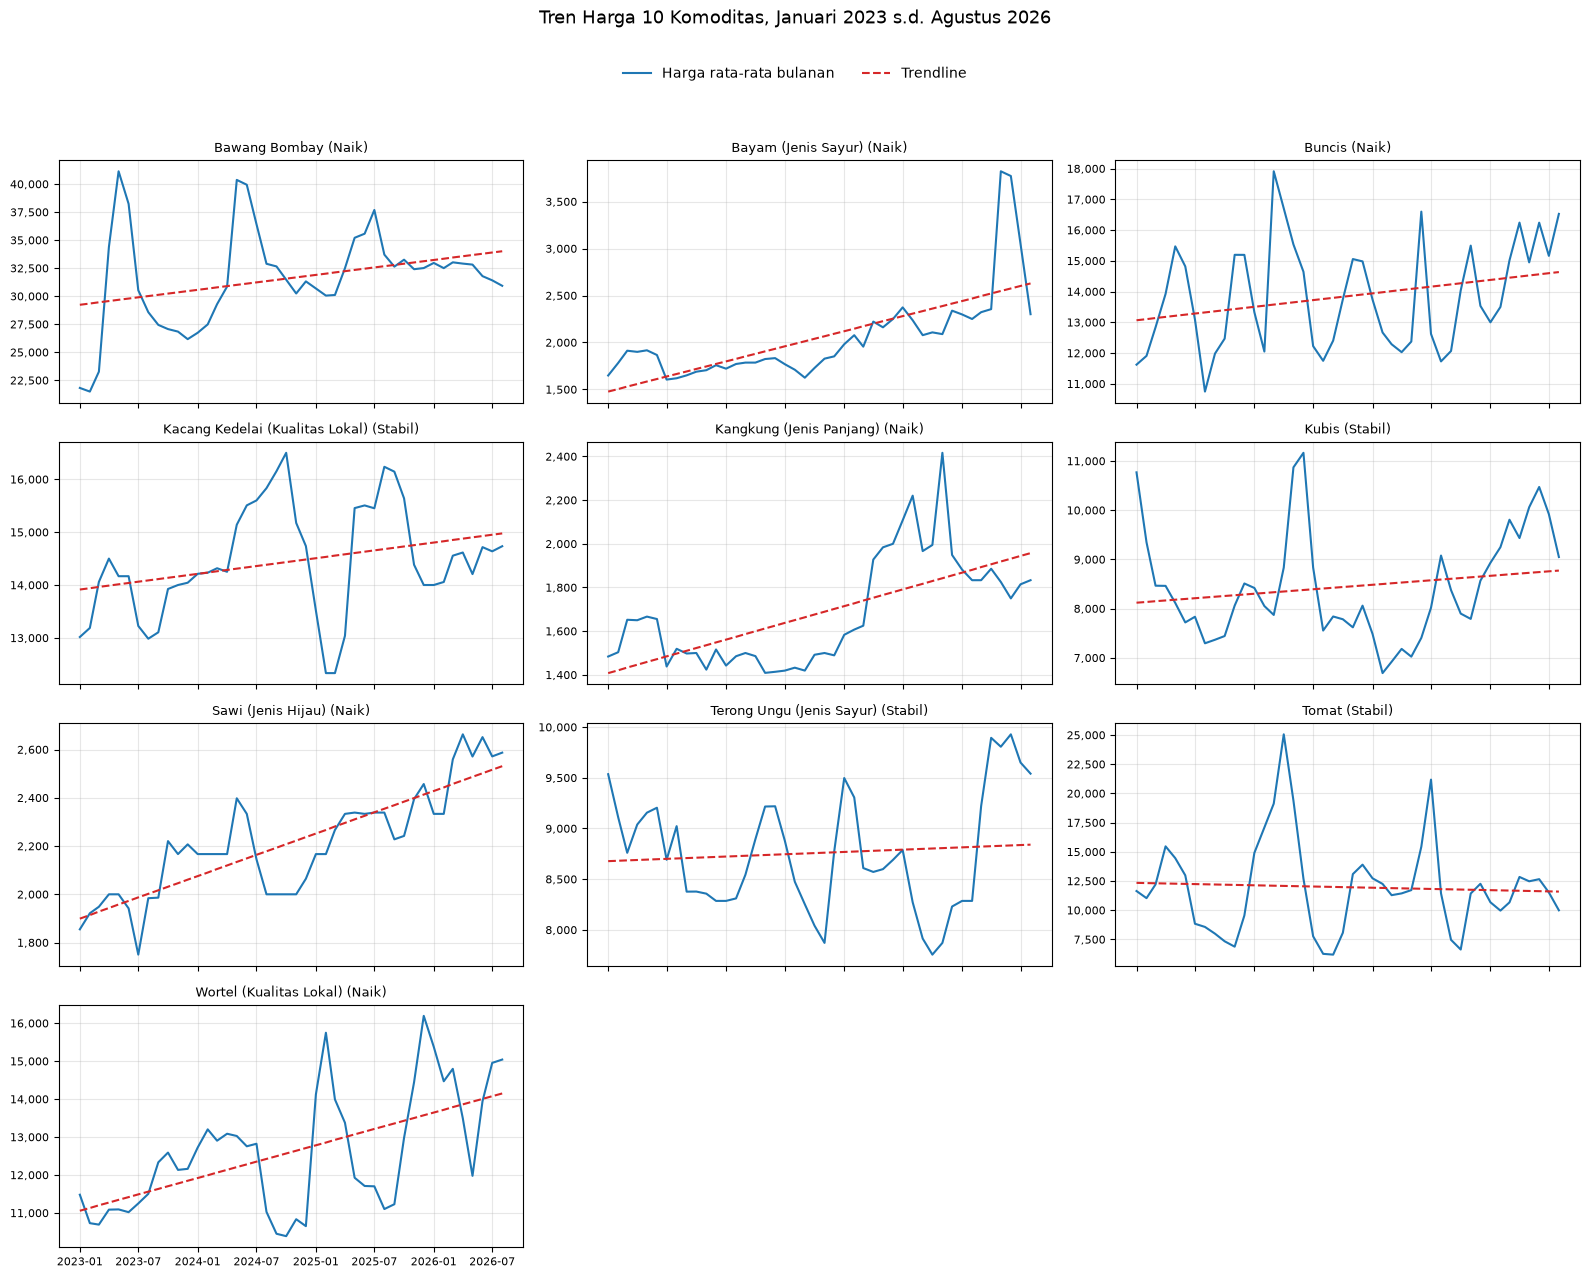

arah_tren
Naik      6
Stabil    4


,harga_awal,harga_akhir,perubahan_total_pct,slope_rp_per_bulan,slope_pct_per_bulan,r2,arah_tren
komoditas,,,,,,,
Bayam (Jenis Sayur),1648.0,2301.0,39.60,27.0,1.30,0.51,Naik
Kangkung (Jenis Panjang),1484.0,1833.0,23.55,13.0,0.76,0.43,Naik
Sawi (Jenis Hijau),1855.0,2587.0,39.48,15.0,0.66,0.71,Naik
Wortel (Kualitas Lokal),11479.0,15041.0,31.03,72.0,0.57,0.34,Naik
Bawang Bombay,21816.0,30925.0,41.76,111.0,0.35,0.11,Naik
Buncis,11622.0,16527.0,42.20,36.0,0.26,0.07,Naik
Kubis,10770.0,9048.0,-15.98,15.0,0.18,0.03,Stabil
Kacang Kedelai (Kualitas Lokal),13016.0,14734.0,13.20,25.0,0.17,0.09,Stabil
Terong Ungu (Jenis Sayur),9535.0,9541.0,0.06,4.0,0.04,0.01,Stabil


In [18]:
%pip install matplotlib
# individual linear regression
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

Path("../reports/figures").mkdir(parents=True, exist_ok=True)
Path("../reports/tables").mkdir(parents=True, exist_ok=True)

AMBANG_TREN = 0.25   # kemiringan tren (% dari rata-rata per bulan) yang dianggap naik atau turun

komoditas_list = list(rata.columns)
x_tgl = rata.index.to_timestamp()
x_num = np.arange(len(rata))

baris = []
garis_tren = {}
for nama in komoditas_list:
    y = rata[nama].to_numpy(dtype=float)
    ada = ~np.isnan(y)

    # Trendline linear: harga = slope x bulan ke-t + intercept
    slope, intercept = np.polyfit(x_num[ada], y[ada], 1)
    prediksi = slope * x_num + intercept
    ss_res = np.sum((y[ada] - prediksi[ada]) ** 2)
    ss_tot = np.sum((y[ada] - y[ada].mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    slope_pct = slope / y[ada].mean() * 100
    if slope_pct >= AMBANG_TREN:
        arah = "Naik"
    elif slope_pct <= -AMBANG_TREN:
        arah = "Turun"
    else:
        arah = "Stabil"

    garis_tren[nama] = prediksi
    baris.append({
        "komoditas": nama,
        "harga_awal": y[ada][0],
        "harga_akhir": y[ada][-1],
        "perubahan_total_pct": (y[ada][-1] - y[ada][0]) / y[ada][0] * 100,
        "slope_rp_per_bulan": slope,
        "slope_pct_per_bulan": slope_pct,
        "r2": r2,
        "arah_tren": arah,
    })

tren_harga = pd.DataFrame(baris).set_index("komoditas")
tren_harga[["harga_awal", "harga_akhir", "slope_rp_per_bulan"]] = (
    tren_harga[["harga_awal", "harga_akhir", "slope_rp_per_bulan"]].round(0)
)
tren_harga[["perubahan_total_pct", "slope_pct_per_bulan", "r2"]] = (
    tren_harga[["perubahan_total_pct", "slope_pct_per_bulan", "r2"]].round(2)
)
tren_harga = tren_harga.sort_values("slope_pct_per_bulan", ascending=False)
tren_harga.to_csv("../reports/tables/tren_harga.csv")

# Line chart + trendline, satu panel per komoditas
n = len(komoditas_list)
kolom = 3
jumlah_baris = int(np.ceil(n / kolom))
fig, axes = plt.subplots(jumlah_baris, kolom, figsize=(16, 3.2 * jumlah_baris), sharex=True)
axes = axes.flatten()

for ax, nama in zip(axes, komoditas_list):
    ax.plot(x_tgl, rata[nama], color="#1f77b4", linewidth=1.5, label="Harga rata-rata bulanan")
    ax.plot(x_tgl, garis_tren[nama], color="#d62728", linestyle="--", linewidth=1.5, label="Trendline")
    ax.set_title(f"{nama} ({tren_harga.loc[nama, 'arah_tren']})", fontsize=9)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3)

for ax in axes[n:]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()

fig.suptitle("Tren Harga 10 Komoditas, Januari 2023 s.d. Agustus 2026", y=0.995, fontsize=13)
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig("../reports/figures/tren_harga.png", dpi=150, bbox_inches="tight")
plt.show()

print(tren_harga["arah_tren"].value_counts().to_string())
tren_harga

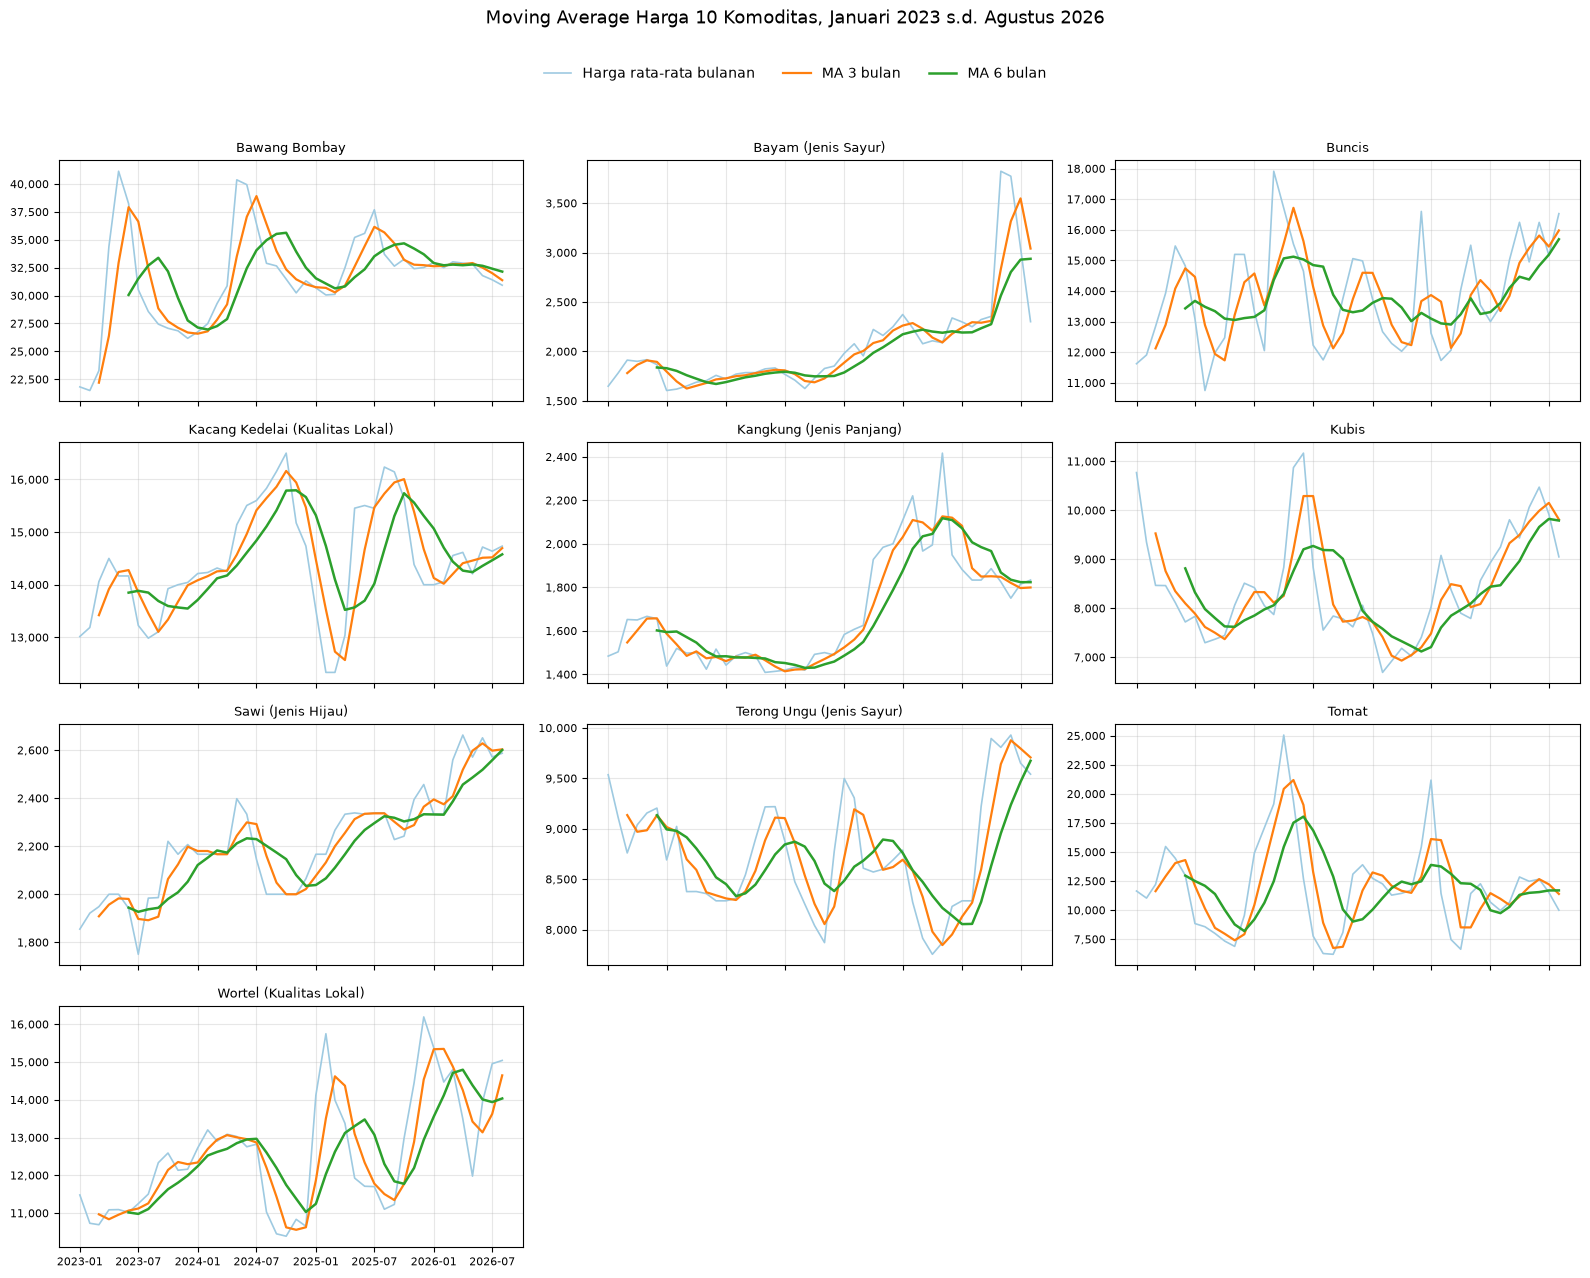

Bulan terakhir: 2026-08


,harga_rata2,ma3,ma6,selisih_ma3_pct,selisih_ma6_pct,posisi_vs_ma6
komoditas,,,,,,
Wortel (Kualitas Lokal),15041.0,14646.0,14034.0,2.70,7.18,Di atas MA6
Buncis,16527.0,15976.0,15689.0,3.45,5.34,Di atas MA6
Kacang Kedelai (Kualitas Lokal),14734.0,14696.0,14577.0,0.26,1.08,Di atas MA6
Kangkung (Jenis Panjang),1833.0,1799.0,1824.0,1.89,0.49,Di atas MA6
Sawi (Jenis Hijau),2587.0,2603.0,2601.0,-0.61,-0.54,Di bawah MA6
Terong Ungu (Jenis Sayur),9541.0,9707.0,9674.0,-1.71,-1.37,Di bawah MA6
Bawang Bombay,30925.0,31375.0,32144.0,-1.43,-3.79,Di bawah MA6
Kubis,9048.0,9813.0,9790.0,-7.80,-7.58,Di bawah MA6
Tomat,9989.0,11387.0,11692.0,-12.28,-14.57,Di bawah MA6


In [19]:
# Moving average (MA) 3 bulan, 6 bulan
JENDELA_MA = {"ma3": 3, "ma6": 6}   # jendela dalam bulan: jangka pendek dan menengah

# Moving average dihitung dari rata-rata bulanan (window penuh, tanpa pengisian bulan kosong)
ma = {nama: rata.rolling(window=w, min_periods=w).mean() for nama, w in JENDELA_MA.items()}

# Gabungkan ke format panjang
moving_average = panjang(rata, "harga_rata2")
for nama, wide in ma.items():
    moving_average = moving_average.merge(panjang(wide, nama), on=["komoditas", "bulan"], how="left")

moving_average = moving_average.sort_values(["komoditas", "bulan"]).reset_index(drop=True)
moving_average[["harga_rata2", *JENDELA_MA]] = moving_average[["harga_rata2", *JENDELA_MA]].round(0)
moving_average.to_csv("../reports/tables/moving_average.csv", index=False)

# Line chart + moving average, satu panel per komoditas
n = len(komoditas_list)
kolom = 3
jumlah_baris = int(np.ceil(n / kolom))
fig, axes = plt.subplots(jumlah_baris, kolom, figsize=(16, 3.2 * jumlah_baris), sharex=True)
axes = axes.flatten()

for ax, nama in zip(axes, komoditas_list):
    ax.plot(x_tgl, rata[nama], color="#9ecae1", linewidth=1.2, label="Harga rata-rata bulanan")
    ax.plot(x_tgl, ma["ma3"][nama], color="#ff7f0e", linewidth=1.6, label="MA 3 bulan")
    ax.plot(x_tgl, ma["ma6"][nama], color="#2ca02c", linewidth=1.8, label="MA 6 bulan")
    ax.set_title(nama, fontsize=9)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3)

for ax in axes[n:]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Moving Average Harga 10 Komoditas, Januari 2023 s.d. Agustus 2026", y=0.995, fontsize=13)
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.93])   # sisakan ruang di atas untuk judul dan legenda
fig.savefig("../reports/figures/moving_average.png", dpi=150, bbox_inches="tight")
plt.show()

# Posisi harga bulan terakhir terhadap moving average
terakhir = moving_average[moving_average["bulan"] == moving_average["bulan"].max()].set_index("komoditas")
terakhir["selisih_ma3_pct"] = ((terakhir["harga_rata2"] - terakhir["ma3"]) / terakhir["ma3"] * 100).round(2)
terakhir["selisih_ma6_pct"] = ((terakhir["harga_rata2"] - terakhir["ma6"]) / terakhir["ma6"] * 100).round(2)
terakhir["posisi_vs_ma6"] = np.where(terakhir["harga_rata2"] >= terakhir["ma6"], "Di atas MA6", "Di bawah MA6")

print(f"Bulan terakhir: {moving_average['bulan'].max()}")
terakhir[["harga_rata2", "ma3", "ma6", "selisih_ma3_pct", "selisih_ma6_pct", "posisi_vs_ma6"]].sort_values(
    "selisih_ma6_pct", ascending=False
)

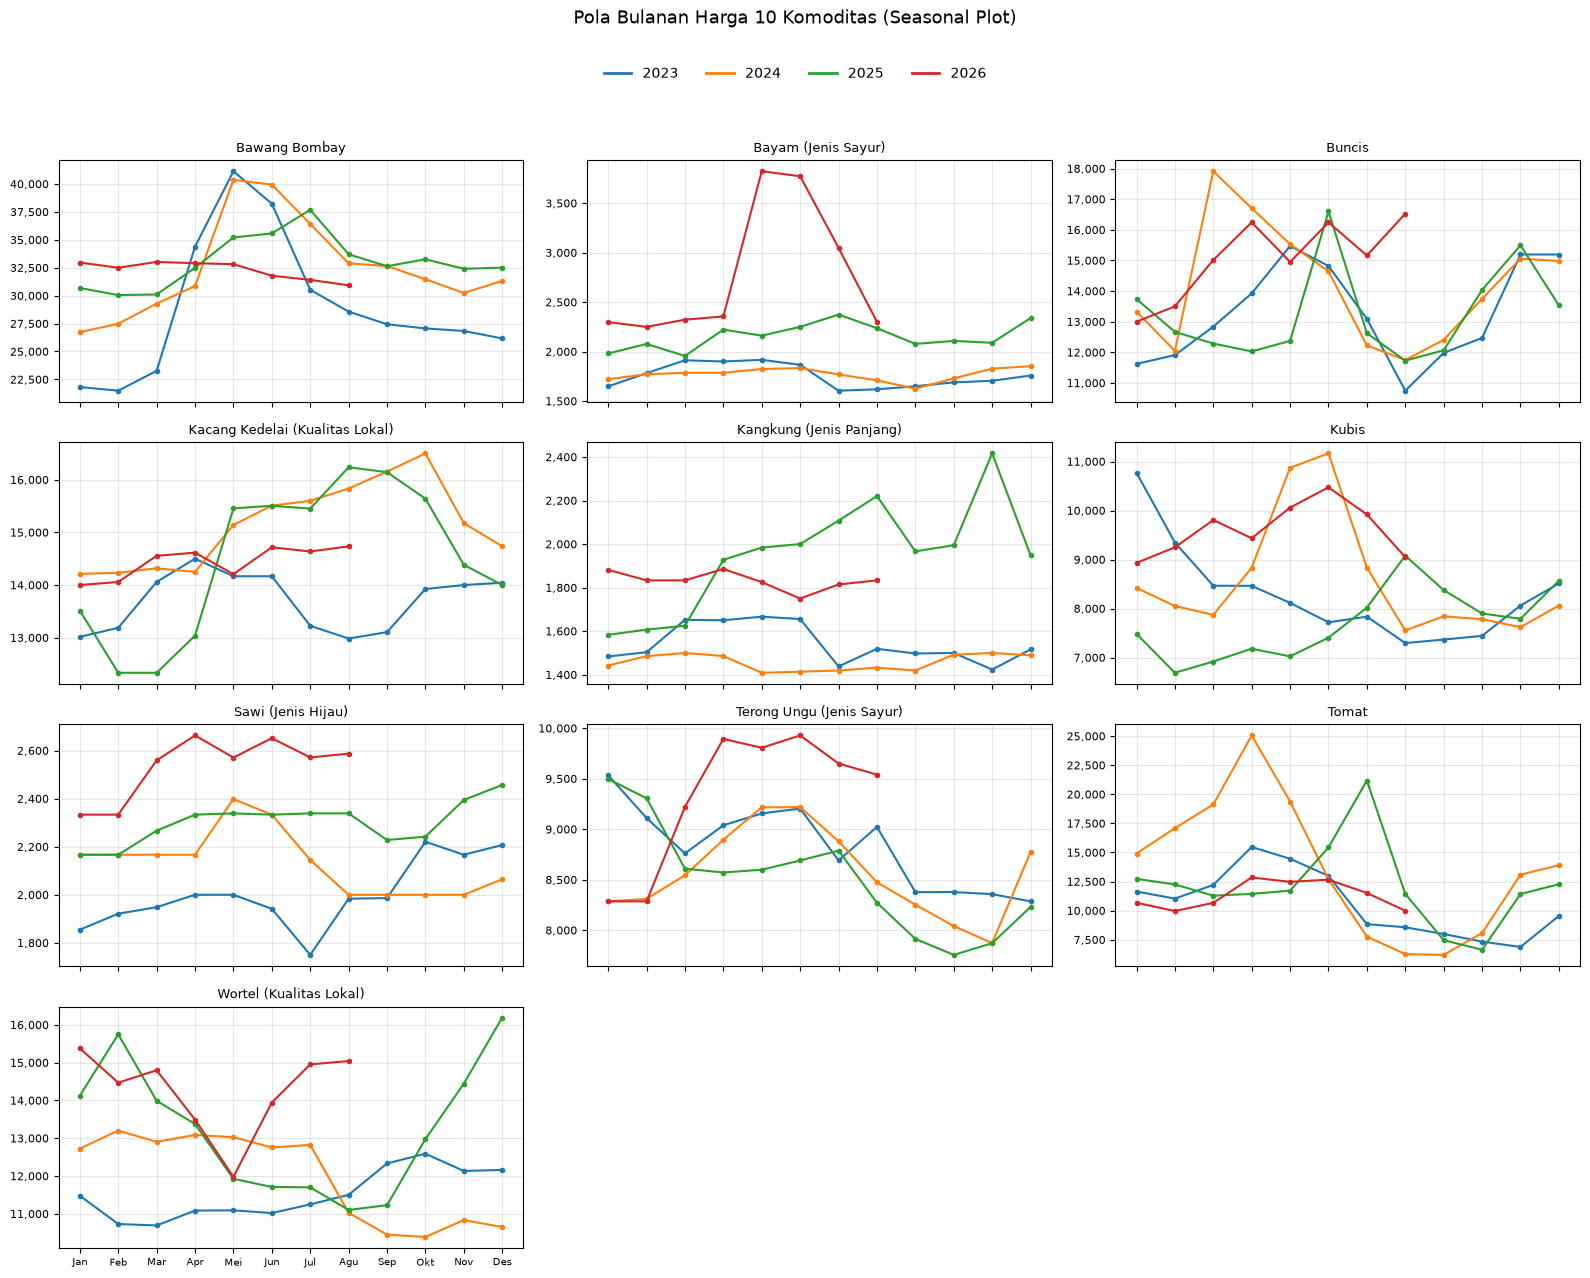

Tahun yang dipakai untuk indeks musiman: [np.int64(2023), np.int64(2024), np.int64(2025)]


,bulan_tertinggi,indeks_tertinggi,bulan_terendah,indeks_terendah,amplitudo,jumlah_tahun
komoditas,,,,,,
Tomat,Apr,141.53,Sep,60.88,80.65,3
Bawang Bombay,Mei,124.41,Feb,83.32,41.09,3
Buncis,Jun,113.32,Agu,84.05,29.27,3
Wortel (Kualitas Lokal),Feb,107.53,Agu,92.00,15.53,3
Kacang Kedelai (Kualitas Lokal),Okt,106.16,Feb,91.78,14.38,3
Kangkung (Jenis Panjang),Nov,106.42,Jan,92.15,14.27,3
Kubis,Jan,108.46,Okt,94.39,14.07,3
Terong Ungu (Jenis Sayur),Jan,105.47,Nov,93.04,12.43,3
Bayam (Jenis Sayur),Jun,104.79,Sep,94.09,10.70,3


In [20]:
NAMA_BULAN = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
              7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}

# Harga rata-rata bulanan dalam format panjang
pb = panjang(rata, "harga_rata2").dropna(subset=["harga_rata2"]).copy()
pb["tahun"] = pb["bulan"].dt.year
pb["bulan_ke"] = pb["bulan"].dt.month

# Indeks musiman: harga bulan tersebut dibagi rata-rata tahunnya x 100 (100 = rata-rata tahun itu)
# Hanya tahun dengan 12 bulan valid yang dipakai, supaya tahun parsial tidak membiasakan indeks
pb["jumlah_bulan"] = pb.groupby(["komoditas", "tahun"])["harga_rata2"].transform("size")
pb["rata_tahun"] = pb.groupby(["komoditas", "tahun"])["harga_rata2"].transform("mean")
pb["indeks"] = pb["harga_rata2"] / pb["rata_tahun"] * 100

dasar_indeks = pb[pb["jumlah_bulan"] == 12]

pola_bulanan = (
    dasar_indeks.groupby(["komoditas", "bulan_ke"])
    .agg(indeks_musiman=("indeks", "mean"), jumlah_tahun=("tahun", "nunique"))
    .reset_index()
)
pola_bulanan["nama_bulan"] = pola_bulanan["bulan_ke"].map(NAMA_BULAN)
pola_bulanan["indeks_musiman"] = pola_bulanan["indeks_musiman"].round(2)
pola_bulanan.to_csv("../reports/tables/pola_bulanan.csv", index=False)

# Ringkasan: bulan cenderung tertinggi dan terendah per komoditas
wide_indeks = pola_bulanan.pivot(index="komoditas", columns="bulan_ke", values="indeks_musiman")
pola_ringkas = pd.DataFrame({
    "bulan_tertinggi": wide_indeks.idxmax(axis=1).map(NAMA_BULAN),
    "indeks_tertinggi": wide_indeks.max(axis=1),
    "bulan_terendah": wide_indeks.idxmin(axis=1).map(NAMA_BULAN),
    "indeks_terendah": wide_indeks.min(axis=1),
    "amplitudo": (wide_indeks.max(axis=1) - wide_indeks.min(axis=1)).round(2),
    "jumlah_tahun": dasar_indeks.groupby("komoditas")["tahun"].nunique(),
}).sort_values("amplitudo", ascending=False)
pola_ringkas.to_csv("../reports/tables/pola_bulanan_ringkas.csv")

# Seasonal plot: sumbu x = bulan (Jan sampai Des), satu garis per tahun
tahun_list = sorted(pb["tahun"].unique())
warna = {t: plt.cm.tab10(i) for i, t in enumerate(tahun_list)}

n = len(komoditas_list)
kolom = 3
jumlah_baris = int(np.ceil(n / kolom))
fig, axes = plt.subplots(jumlah_baris, kolom, figsize=(16, 3.2 * jumlah_baris), sharex=True)
axes = axes.flatten()

for ax, nama in zip(axes, komoditas_list):
    tabel = pb[pb["komoditas"] == nama].pivot(index="bulan_ke", columns="tahun", values="harga_rata2")
    for t in tabel.columns:
        ax.plot(tabel.index, tabel[t], color=warna[t], linewidth=1.5, marker="o", markersize=3, label=str(t))
    ax.set_title(nama, fontsize=9)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([NAMA_BULAN[m] for m in range(1, 13)], fontsize=7)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(alpha=0.3)

for ax in axes[n:]:
    ax.set_visible(False)

handles = [plt.Line2D([0], [0], color=warna[t], linewidth=2) for t in tahun_list]
fig.suptitle("Pola Bulanan Harga 10 Komoditas (Seasonal Plot)", y=0.995, fontsize=13)
fig.legend(handles, [str(t) for t in tahun_list], loc="upper center",
           bbox_to_anchor=(0.5, 0.96), ncol=len(tahun_list), frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("../reports/figures/pola_bulanan.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Tahun yang dipakai untuk indeks musiman: {sorted(dasar_indeks['tahun'].unique())}")
pola_ringkas

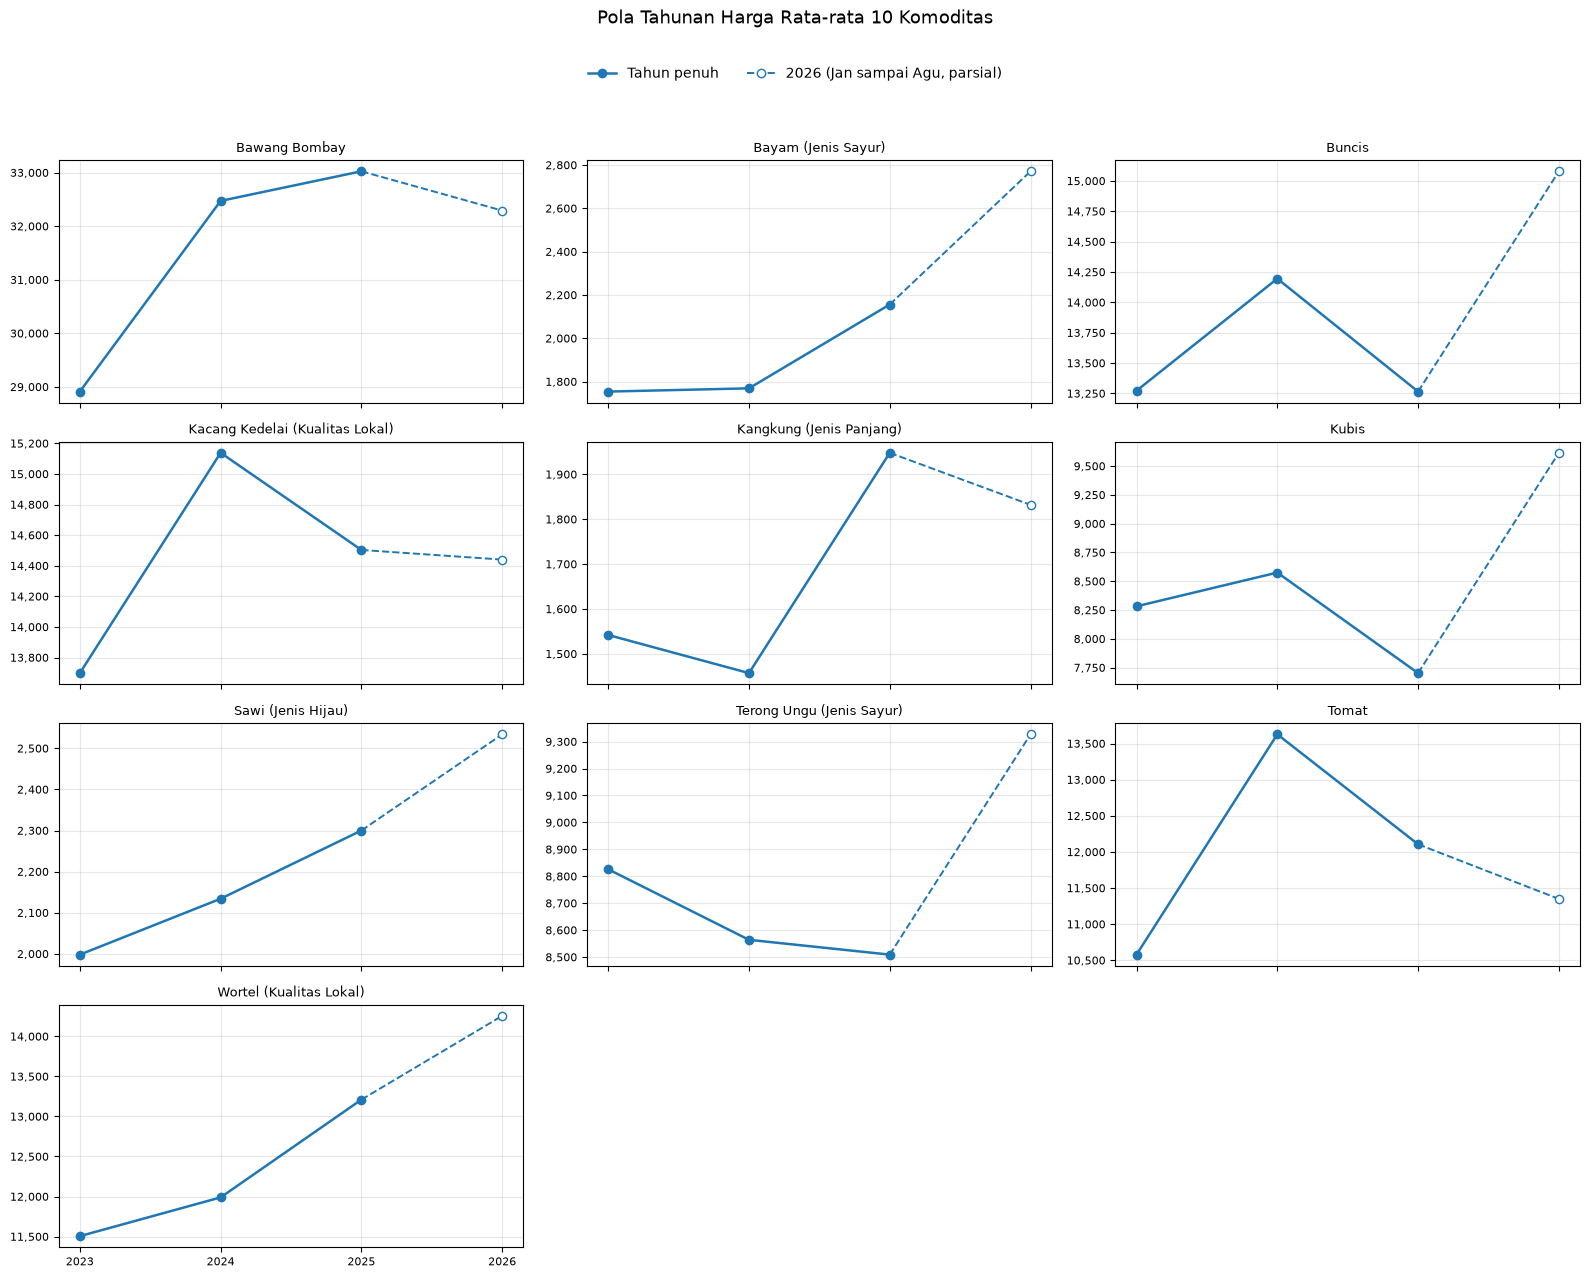

komoditas,Bawang Bombay,Bayam (Jenis Sayur),Buncis,Kacang Kedelai (Kualitas Lokal),Kangkung (Jenis Panjang),Kubis,Sawi (Jenis Hijau),Terong Ungu (Jenis Sayur),Tomat,Wortel (Kualitas Lokal)
tahun,,,,,,,,,,
2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024,12.31,0.86,6.95,10.51,-5.50,3.54,6.79,-2.98,28.82,4.20
2025,1.70,21.84,-6.55,-4.19,33.70,-10.18,7.80,-0.64,-11.17,10.18
2026,-2.70,28.46,15.95,1.45,-2.64,28.63,10.87,6.08,-15.52,10.01


In [21]:
TAHUN_AKHIR = rata.index.max().year
BULAN_AKHIR = rata.index.max().month
ADA_PARSIAL = BULAN_AKHIR < 12

# Harga rata-rata tahunan (rata-rata dari rata-rata bulanan yang valid)
rata_tahunan = (
    pb.groupby(["komoditas", "tahun"])
    .agg(rata2_harga=("harga_rata2", "mean"), bulan_tercatat=("bulan_ke", "nunique"))
    .reset_index()
)
rata_tahunan["tahun_parsial"] = ADA_PARSIAL & (rata_tahunan["tahun"] == TAHUN_AKHIR)

# Perubahan vs tahun sebelumnya, hanya dari bulan yang tersedia di kedua tahun (periode sebanding)
tab = pb.pivot_table(index=["komoditas", "bulan_ke"], columns="tahun", values="harga_rata2")


def hitung_perubahan(r):
    t = r["tahun"]
    if (t - 1) not in tab.columns:
        return pd.Series({"perubahan_vs_tahun_lalu_pct": np.nan, "bulan_sebanding": 0})
    sub = tab.loc[r["komoditas"]][[t - 1, t]].dropna()
    if sub.empty:
        return pd.Series({"perubahan_vs_tahun_lalu_pct": np.nan, "bulan_sebanding": 0})
    return pd.Series({
        "perubahan_vs_tahun_lalu_pct": ubah(sub[t].mean(), sub[t - 1].mean()),
        "bulan_sebanding": len(sub),
    })


rata_tahunan = pd.concat([rata_tahunan, rata_tahunan.apply(hitung_perubahan, axis=1)], axis=1)
rata_tahunan["rata2_harga"] = rata_tahunan["rata2_harga"].round(0)
rata_tahunan["perubahan_vs_tahun_lalu_pct"] = rata_tahunan["perubahan_vs_tahun_lalu_pct"].round(2)
rata_tahunan["bulan_sebanding"] = rata_tahunan["bulan_sebanding"].astype(int)
rata_tahunan = rata_tahunan.sort_values(["komoditas", "tahun"]).reset_index(drop=True)
rata_tahunan.to_csv("../reports/tables/pola_tahunan.csv", index=False)

# Line chart per tahun, satu panel per komoditas
tahun_x = sorted(rata_tahunan["tahun"].unique())
n = len(komoditas_list)
kolom = 3
jumlah_baris = int(np.ceil(n / kolom))
fig, axes = plt.subplots(jumlah_baris, kolom, figsize=(16, 3.2 * jumlah_baris), sharex=True)
axes = axes.flatten()

for ax, nama in zip(axes, komoditas_list):
    d = rata_tahunan[rata_tahunan["komoditas"] == nama]
    penuh = d[~d["tahun_parsial"]]
    parsial = d[d["tahun_parsial"]]

    ax.plot(penuh["tahun"], penuh["rata2_harga"], color="#1f77b4", marker="o", linewidth=1.8)
    if not parsial.empty:
        sambung = pd.concat([penuh.tail(1), parsial])
        ax.plot(sambung["tahun"], sambung["rata2_harga"], color="#1f77b4", linestyle="--", linewidth=1.4)
        ax.scatter(parsial["tahun"], parsial["rata2_harga"], facecolors="white",
                   edgecolors="#1f77b4", s=35, zorder=3)

    ax.set_title(nama, fontsize=9)
    ax.set_xticks(tahun_x)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3)

for ax in axes[n:]:
    ax.set_visible(False)

handles = [
    plt.Line2D([0], [0], color="#1f77b4", marker="o", linewidth=1.8),
    plt.Line2D([0], [0], color="#1f77b4", marker="o", markerfacecolor="white", linestyle="--", linewidth=1.4),
]
label_parsial = f"{TAHUN_AKHIR} (Jan sampai {NAMA_BULAN[BULAN_AKHIR]}, parsial)"
fig.suptitle("Pola Tahunan Harga Rata-rata 10 Komoditas", y=0.995, fontsize=13)
fig.legend(handles, ["Tahun penuh", label_parsial], loc="upper center",
           bbox_to_anchor=(0.5, 0.96), ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("../reports/figures/pola_tahunan.png", dpi=150, bbox_inches="tight")
plt.show()

# Perubahan harga rata-rata vs tahun sebelumnya (baris = tahun, kolom = komoditas)
rata_tahunan.pivot(index="tahun", columns="komoditas", values="perubahan_vs_tahun_lalu_pct")

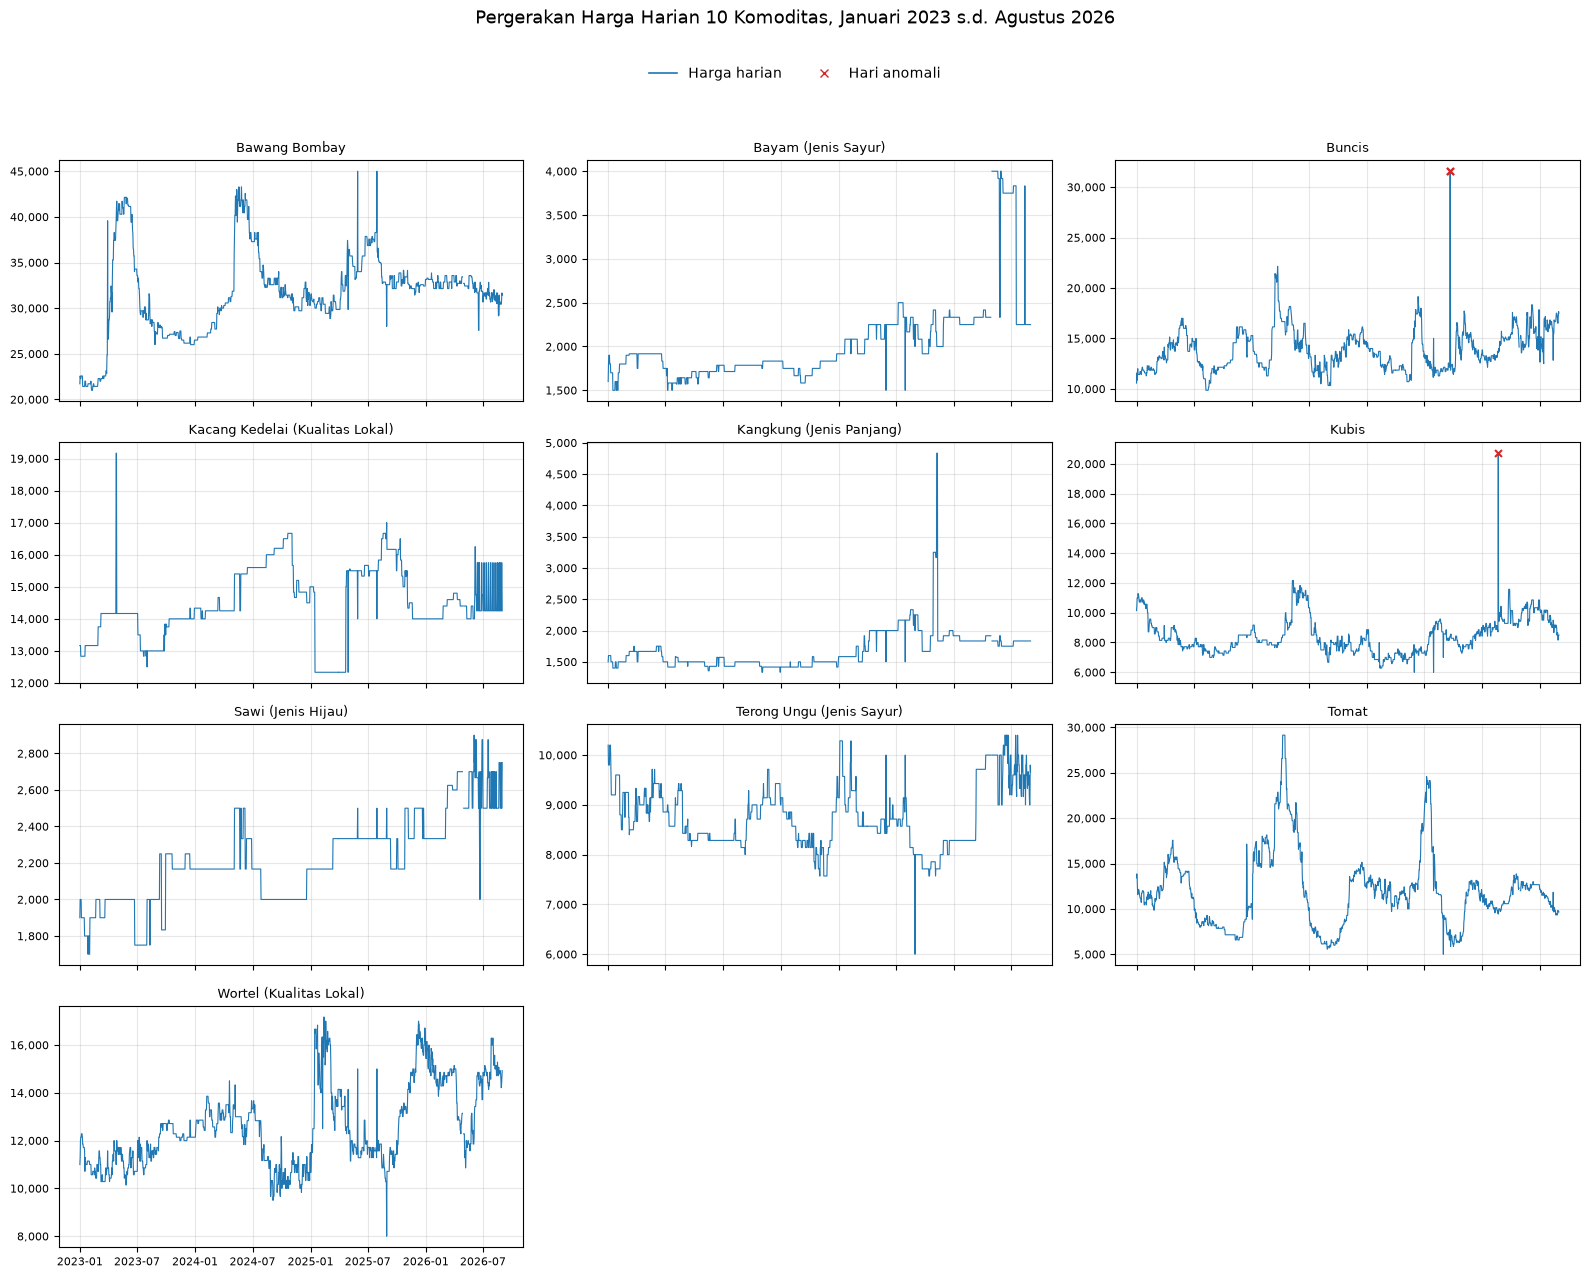

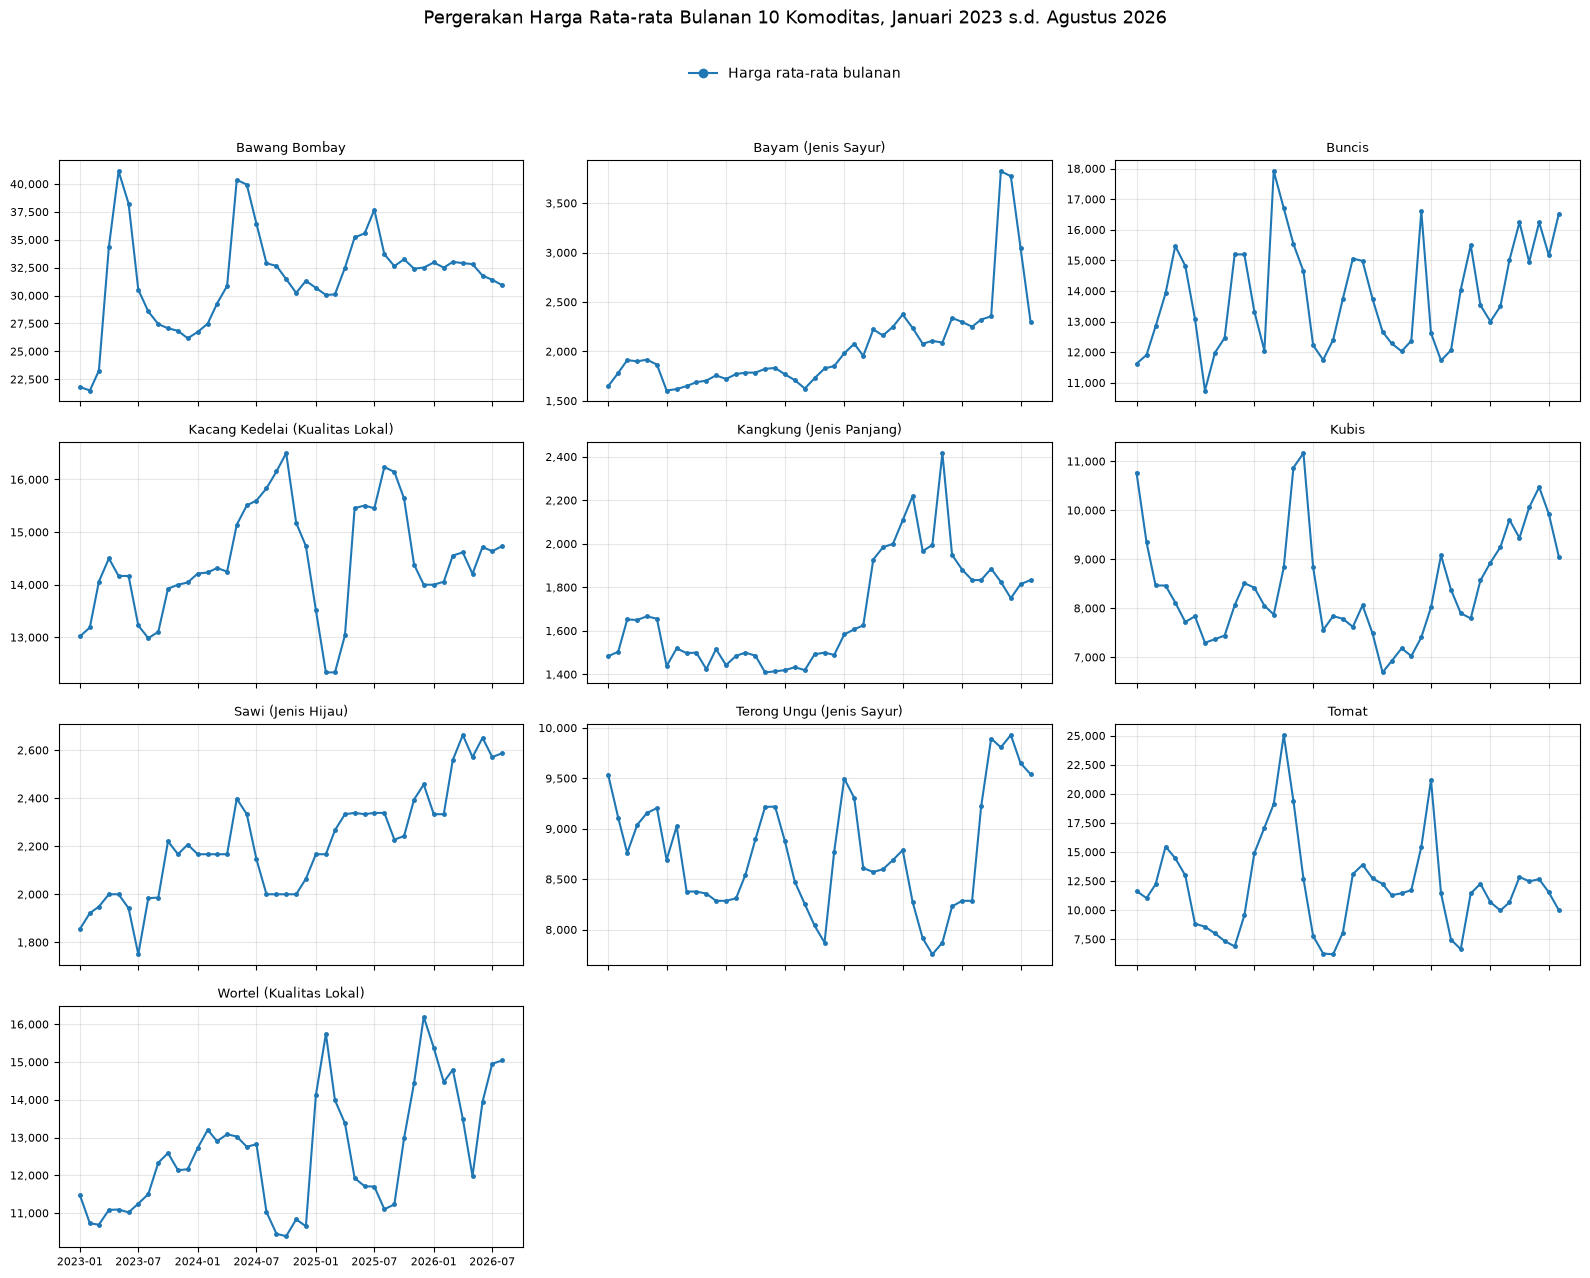

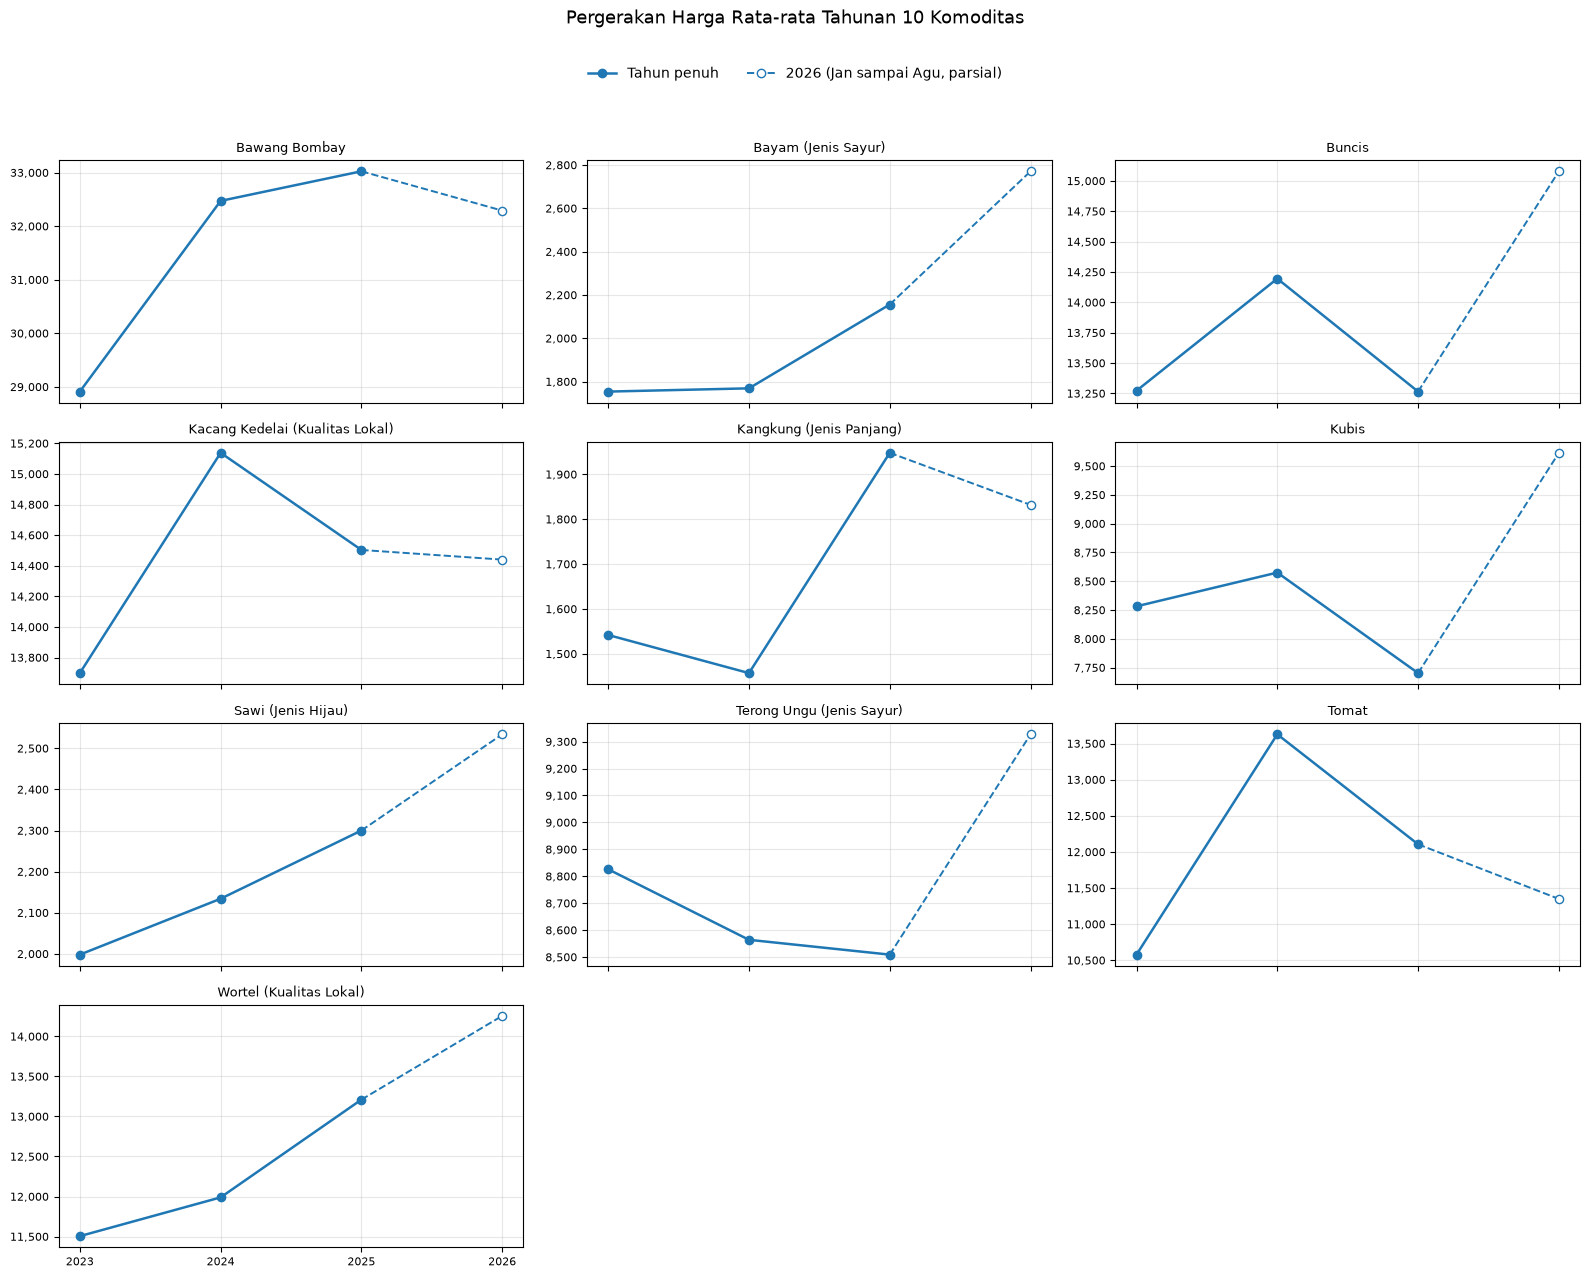

Hari anomali ditandai: 3 | Hari tanpa data (semua komoditas): 4


In [22]:
# plot pergerakan harga harian, bulanan, dan tahunan
def grid_plot(isi, judul, nama_file, handles, labels, ncol=2, kolom=3):
    """Satu panel per komoditas, judul dan legenda tidak saling menimpa."""
    n = len(komoditas_list)
    jumlah_baris = int(np.ceil(n / kolom))
    fig, axes = plt.subplots(jumlah_baris, kolom, figsize=(16, 3.2 * jumlah_baris), sharex=True)
    axes = axes.flatten()
    for ax, nama in zip(axes, komoditas_list):
        isi(ax, nama)
        ax.set_title(nama, fontsize=9)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.tick_params(labelsize=8)
        ax.grid(alpha=0.3)
    for ax in axes[n:]:
        ax.set_visible(False)
    fig.suptitle(judul, y=0.995, fontsize=13)
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=ncol, frameon=False)
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(f"../reports/figures/{nama_file}.png", dpi=150, bbox_inches="tight")
    plt.show()


# ---------- 1. Pergerakan harian ----------
tgl_penuh = pd.date_range(data["tanggal"].min(), data["tanggal"].max(), freq="D")
harian = (
    data.pivot_table(index="tanggal", columns="komoditas", values="harga", aggfunc="mean")
    .reindex(tgl_penuh)          # hari tanpa data menjadi NaN, sehingga garis terputus
)
hari_anomali = data[data["anomali"]]


def isi_harian(ax, nama):
    ax.plot(harian.index, harian[nama], color="#1f77b4", linewidth=0.8)
    s = hari_anomali[hari_anomali["komoditas"] == nama]
    if not s.empty:
        ax.scatter(s["tanggal"], s["harga"], color="#d62728", marker="x", s=25, zorder=3)


grid_plot(
    isi_harian,
    "Pergerakan Harga Harian 10 Komoditas, Januari 2023 s.d. Agustus 2026",
    "pergerakan_harian",
    [plt.Line2D([0], [0], color="#1f77b4", linewidth=1.2),
     plt.Line2D([0], [0], color="#d62728", marker="x", linestyle="")],
    ["Harga harian", "Hari anomali"],
)


# ---------- 2. Pergerakan bulanan ----------
def isi_bulanan(ax, nama):
    ax.plot(x_tgl, rata[nama], color="#1f77b4", linewidth=1.5, marker="o", markersize=2.5)


grid_plot(
    isi_bulanan,
    "Pergerakan Harga Rata-rata Bulanan 10 Komoditas, Januari 2023 s.d. Agustus 2026",
    "pergerakan_bulanan",
    [plt.Line2D([0], [0], color="#1f77b4", marker="o", linewidth=1.5)],
    ["Harga rata-rata bulanan"],
    ncol=1,
)


# ---------- 3. Pergerakan tahunan ----------
def isi_tahunan(ax, nama):
    d = rata_tahunan[rata_tahunan["komoditas"] == nama]
    penuh = d[~d["tahun_parsial"]]
    parsial = d[d["tahun_parsial"]]

    ax.plot(penuh["tahun"], penuh["rata2_harga"], color="#1f77b4", marker="o", linewidth=1.8)
    if not parsial.empty:
        sambung = pd.concat([penuh.tail(1), parsial])
        ax.plot(sambung["tahun"], sambung["rata2_harga"], color="#1f77b4", linestyle="--", linewidth=1.4)
        ax.scatter(parsial["tahun"], parsial["rata2_harga"], facecolors="white",
                   edgecolors="#1f77b4", s=35, zorder=3)
    ax.set_xticks(tahun_x)


label_parsial = f"{TAHUN_AKHIR} (Jan sampai {NAMA_BULAN[BULAN_AKHIR]}, parsial)"
grid_plot(
    isi_tahunan,
    "Pergerakan Harga Rata-rata Tahunan 10 Komoditas",
    "pergerakan_tahunan",
    [plt.Line2D([0], [0], color="#1f77b4", marker="o", linewidth=1.8),
     plt.Line2D([0], [0], color="#1f77b4", marker="o", markerfacecolor="white",
                linestyle="--", linewidth=1.4)],
    ["Tahun penuh", label_parsial],
)
print(f"Hari anomali ditandai: {len(hari_anomali)} | Hari tanpa data (semua komoditas): {int(harian.isna().all(axis=1).sum())}")

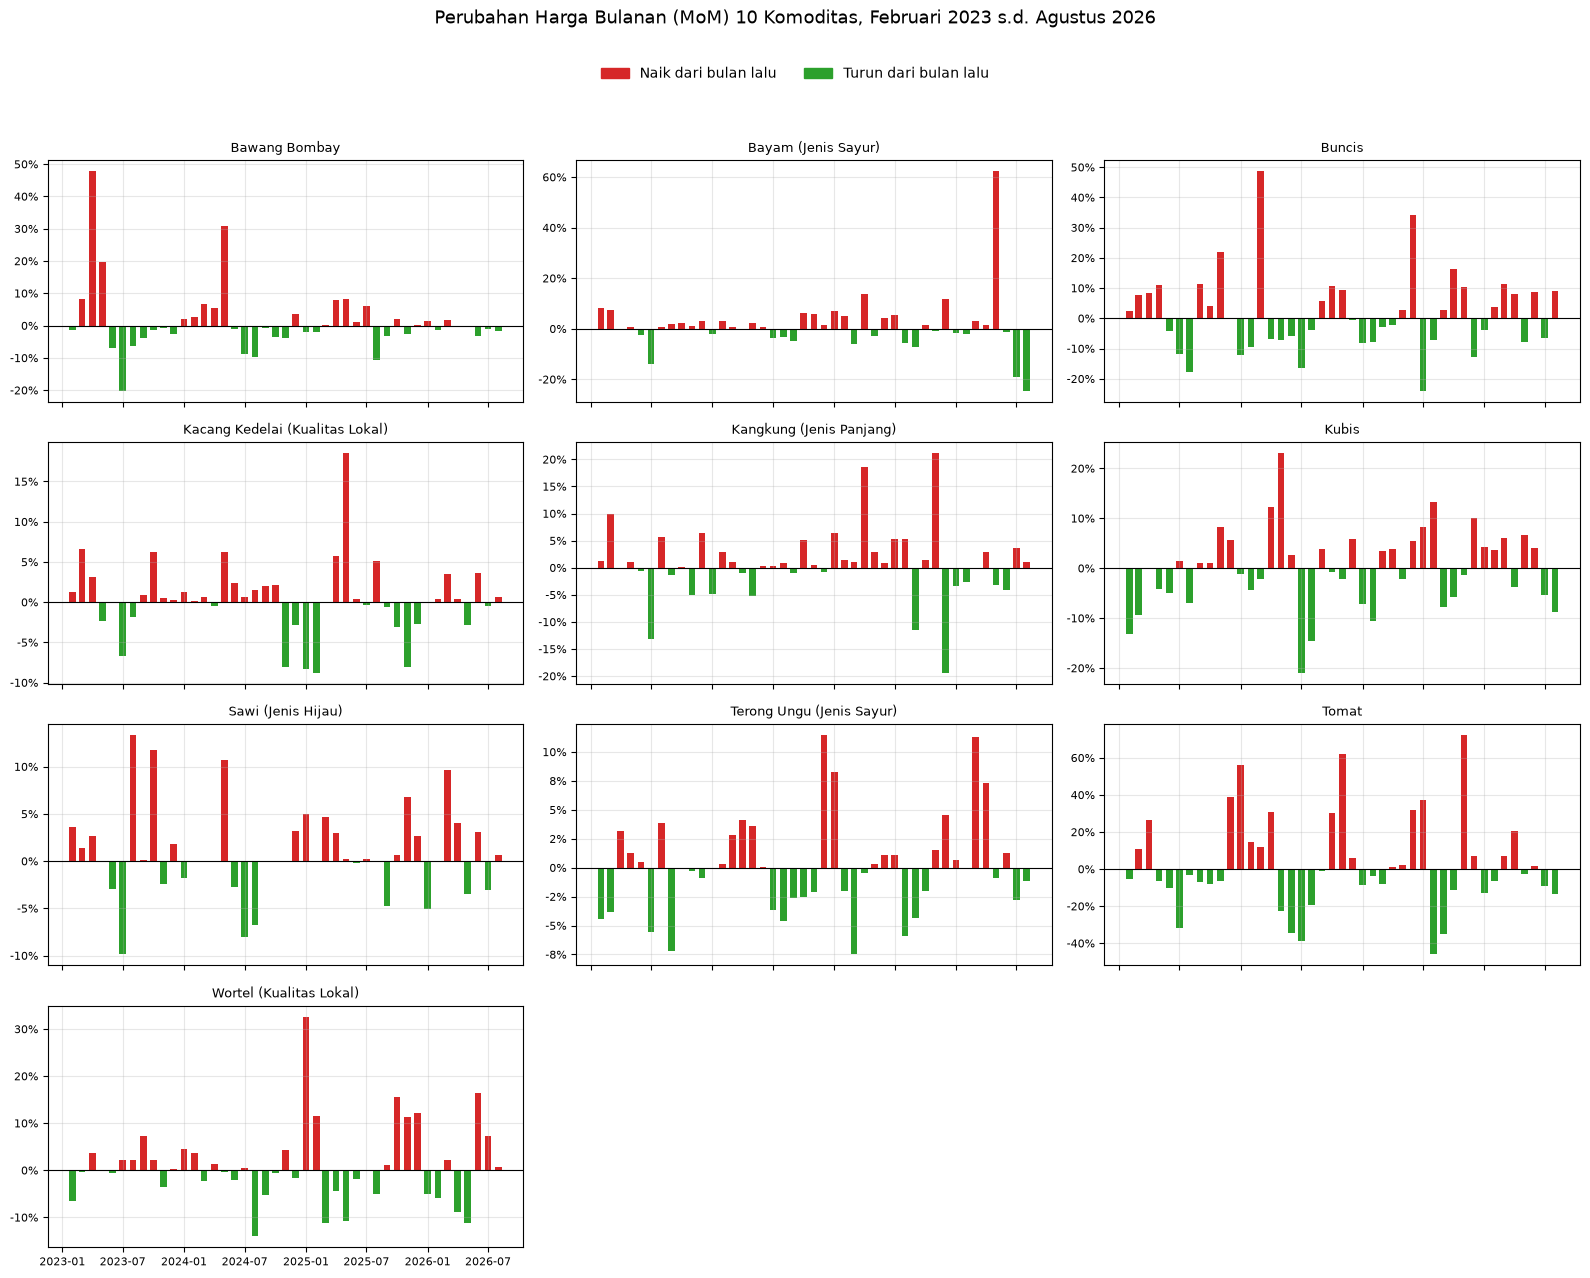

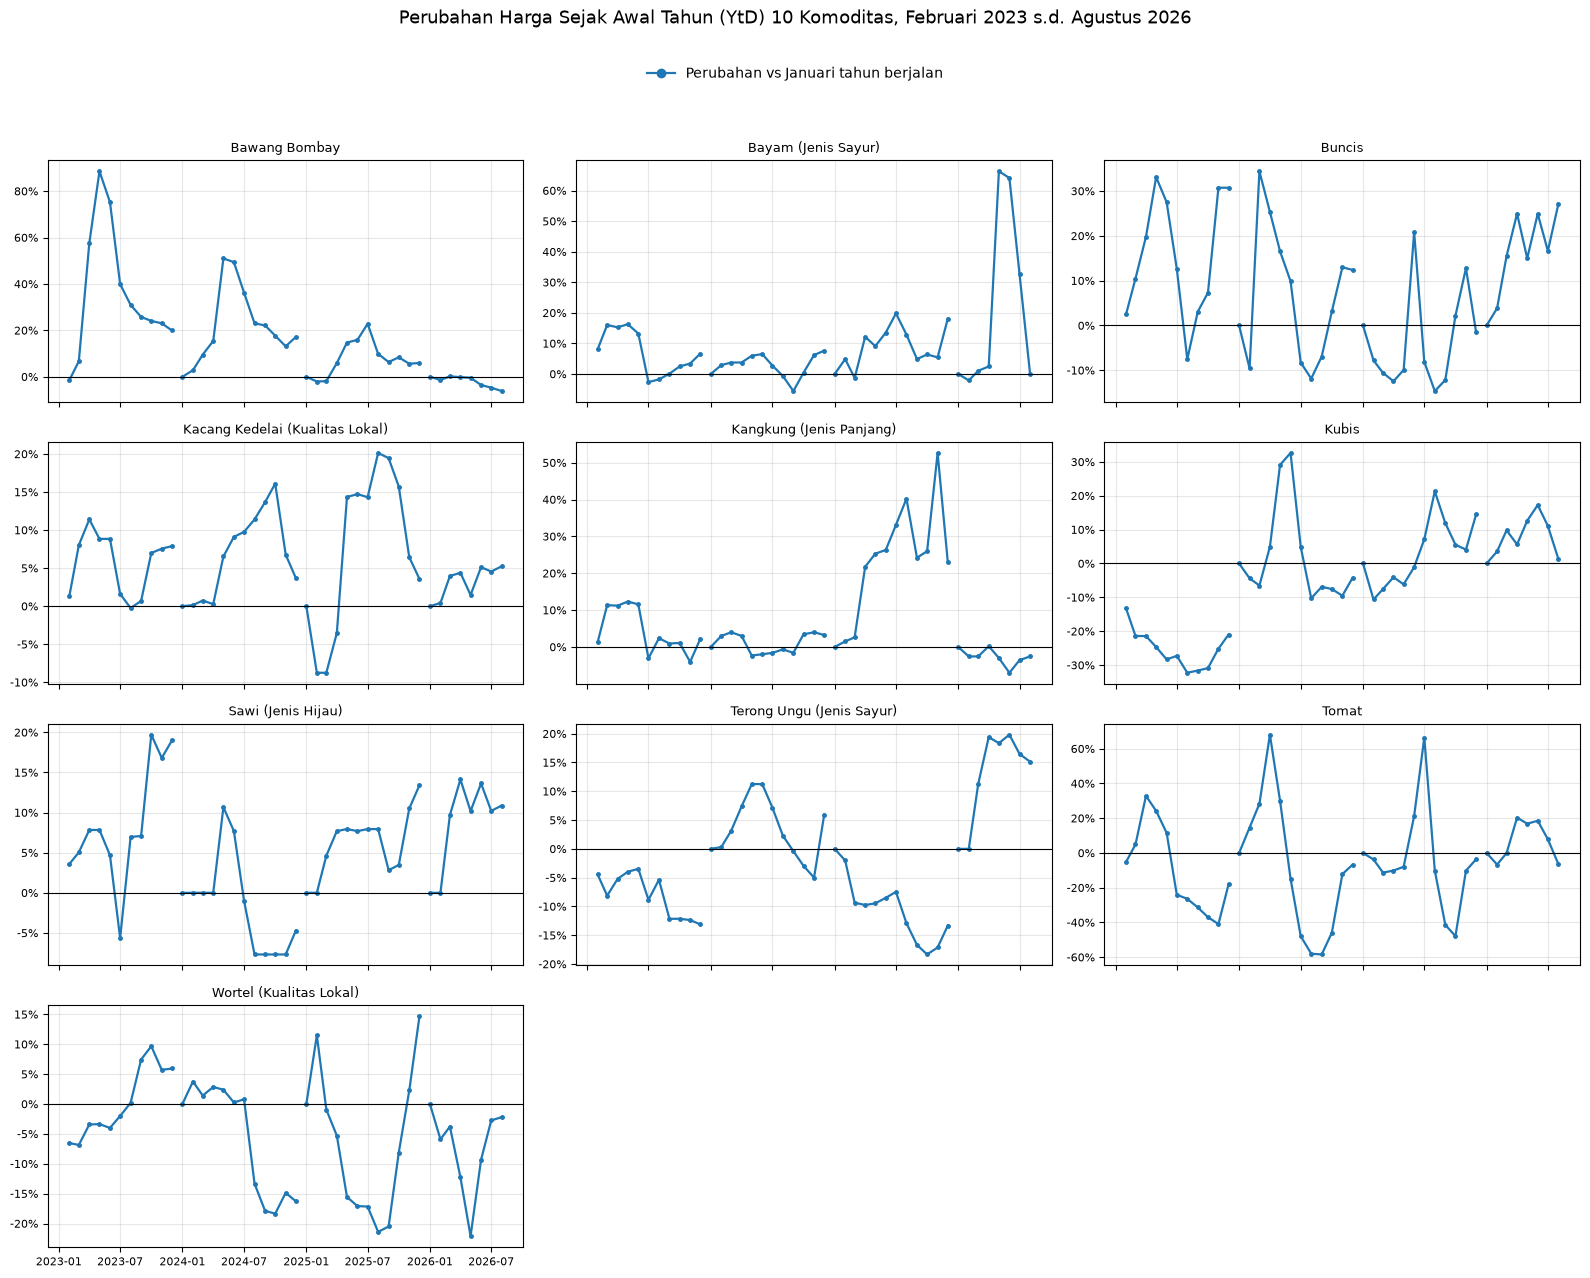

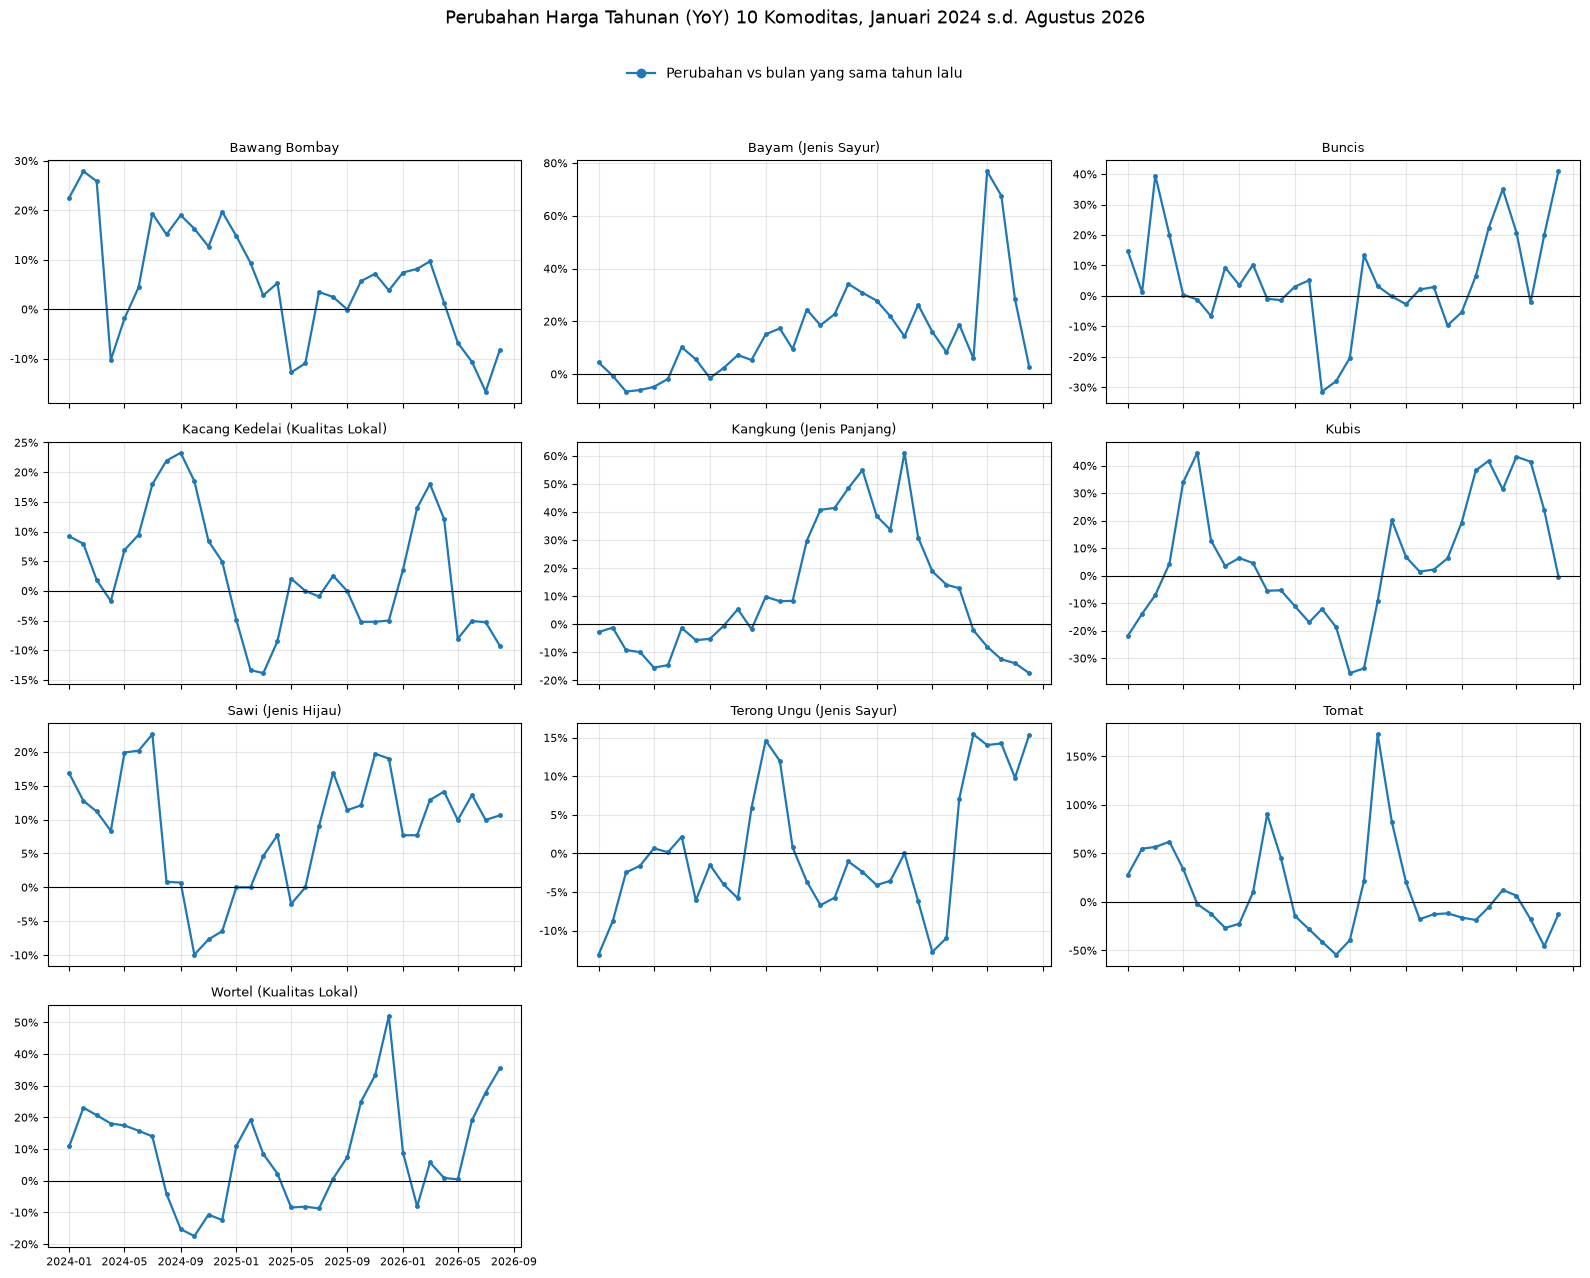

Bulan terakhir: 2026-08


,harga_rata2,mom_pct,ytd_pct,yoy_pct
komoditas,,,,
Buncis,16526.88,9.01,27.13,40.92
Kangkung (Jenis Panjang),1833.33,1.04,-2.57,-17.43
Kacang Kedelai (Kualitas Lokal),14733.87,0.66,5.24,-9.25
Sawi (Jenis Hijau),2587.10,0.61,10.88,10.62
Wortel (Kualitas Lokal),15041.47,0.59,-2.19,35.49
Terong Ungu (Jenis Sayur),9540.86,-1.14,15.15,15.34
Bawang Bombay,30925.50,-1.55,-6.18,-8.25
Kubis,9048.39,-8.78,1.32,-0.33
Tomat,9989.25,-13.26,-6.45,-12.66


In [25]:
def grid_plot(isi, judul, nama_file, handles, labels, ncol=2, kolom=3, fmt="{:,.0f}"):
    """Satu panel per komoditas, judul dan legenda tidak saling menimpa."""
    n = len(komoditas_list)
    jumlah_baris = int(np.ceil(n / kolom))
    fig, axes = plt.subplots(jumlah_baris, kolom, figsize=(16, 3.2 * jumlah_baris), sharex=True)
    axes = axes.flatten()
    for ax, nama in zip(axes, komoditas_list):
        isi(ax, nama)
        ax.set_title(nama, fontsize=9)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt.format(v)))
        ax.tick_params(labelsize=8)
        ax.grid(alpha=0.3)
    for ax in axes[n:]:
        ax.set_visible(False)
    fig.suptitle(judul, y=0.995, fontsize=13)
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=ncol, frameon=False)
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(f"../reports/figures/{nama_file}.png", dpi=150, bbox_inches="tight")
    plt.show()


# Tabel lebar (baris = bulan, kolom = komoditas) dengan indeks tanggal
mom_w = perubahan.pivot(index="bulan", columns="komoditas", values="mom_pct")
ytd_w = perubahan.pivot(index="bulan", columns="komoditas", values="ytd_pct")
yoy_w = yoy_tabel.pivot(index="bulan", columns="komoditas", values="yoy_pct")
for w in (mom_w, ytd_w, yoy_w):
    w.index = w.index.to_timestamp()

WARNA_NAIK, WARNA_TURUN, WARNA_GARIS = "#d62728", "#2ca02c", "#1f77b4"


# ---------- 1. MoM (batang: merah naik, hijau turun) ----------
def isi_mom(ax, nama):
    s = mom_w[nama].dropna()
    ax.bar(s.index, s.values, width=20, color=np.where(s.values >= 0, WARNA_NAIK, WARNA_TURUN))
    ax.axhline(0, color="black", linewidth=0.8)


grid_plot(
    isi_mom,
    "Perubahan Harga Bulanan (MoM) 10 Komoditas, Februari 2023 s.d. Agustus 2026",
    "plot_mom",
    [plt.Rectangle((0, 0), 1, 1, color=WARNA_NAIK), plt.Rectangle((0, 0), 1, 1, color=WARNA_TURUN)],
    ["Naik dari bulan lalu", "Turun dari bulan lalu"],
    fmt="{:,.0f}%",
)


# ---------- 2. YtD (garis, kembali ke 0 setiap Januari) ----------
def isi_ytd(ax, nama):
    s = ytd_w[nama].dropna()
    for _, g in s.groupby(s.index.year):          # satu segmen per tahun, tidak disambung antar tahun
        ax.plot(g.index, g.values, color=WARNA_GARIS, linewidth=1.6, marker="o", markersize=2.5)
    ax.axhline(0, color="black", linewidth=0.8)


grid_plot(
    isi_ytd,
    "Perubahan Harga Sejak Awal Tahun (YtD) 10 Komoditas, Februari 2023 s.d. Agustus 2026",
    "plot_ytd",
    [plt.Line2D([0], [0], color=WARNA_GARIS, marker="o", linewidth=1.6)],
    ["Perubahan vs Januari tahun berjalan"],
    ncol=1,
    fmt="{:,.0f}%",
)


# ---------- 3. YoY (garis, mulai Januari 2024) ----------
def isi_yoy(ax, nama):
    s = yoy_w[nama]
    ax.plot(s.index, s.values, color=WARNA_GARIS, linewidth=1.6, marker="o", markersize=2.5)
    ax.axhline(0, color="black", linewidth=0.8)


grid_plot(
    isi_yoy,
    "Perubahan Harga Tahunan (YoY) 10 Komoditas, Januari 2024 s.d. Agustus 2026",
    "plot_yoy",
    [plt.Line2D([0], [0], color=WARNA_GARIS, marker="o", linewidth=1.6)],
    ["Perubahan vs bulan yang sama tahun lalu"],
    ncol=1,
    fmt="{:,.0f}%",
)


# ---------- Ringkasan bulan terakhir ----------
bulan_akhir = perubahan["bulan"].max()
ringkas = (
    perubahan[perubahan["bulan"] == bulan_akhir]
    .set_index("komoditas")[["harga_rata2", "mom_pct", "ytd_pct"]]
    .join(yoy_tabel[yoy_tabel["bulan"] == bulan_akhir].set_index("komoditas")["yoy_pct"])
)
print(f"Bulan terakhir: {bulan_akhir}")
ringkas.sort_values("mom_pct", ascending=False)

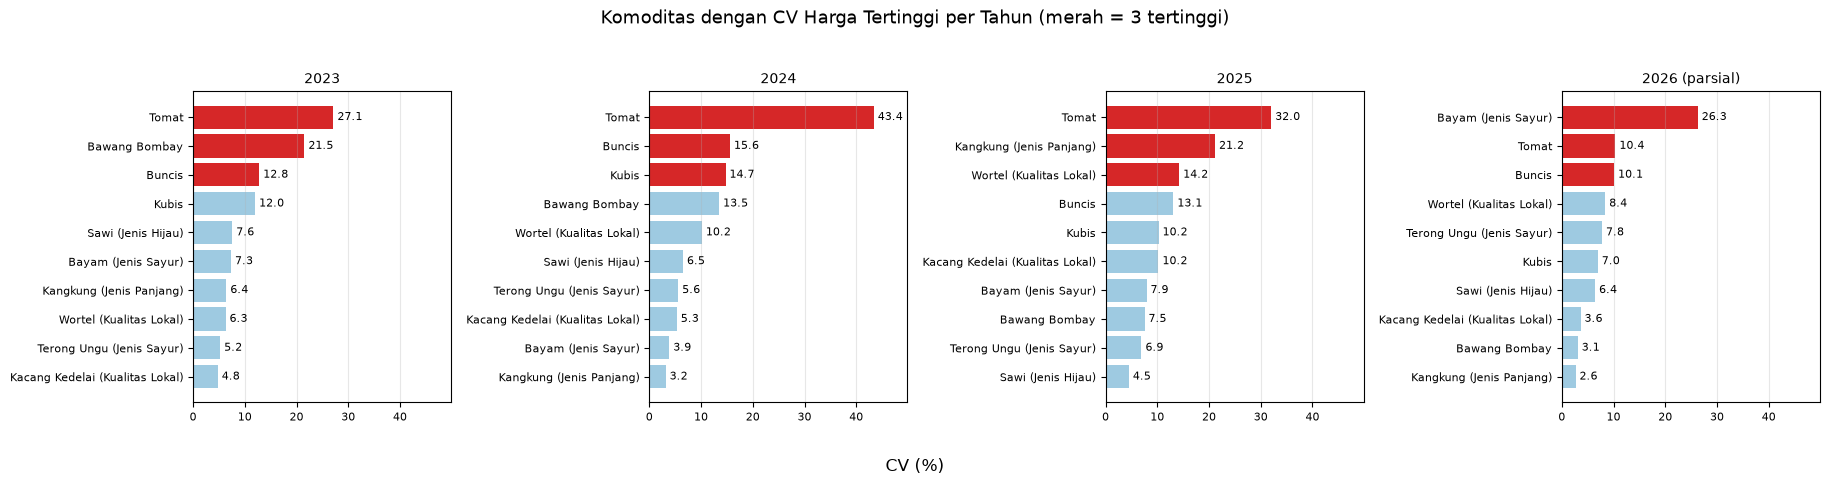

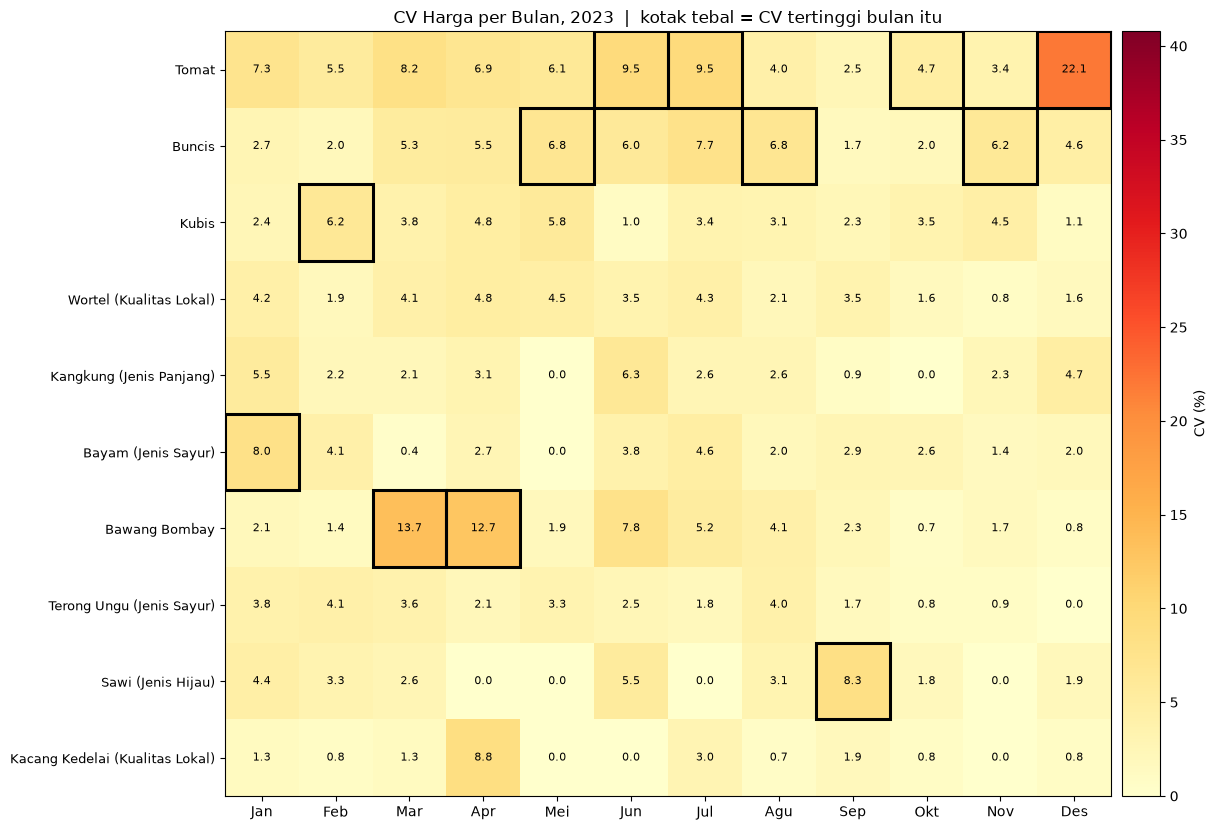

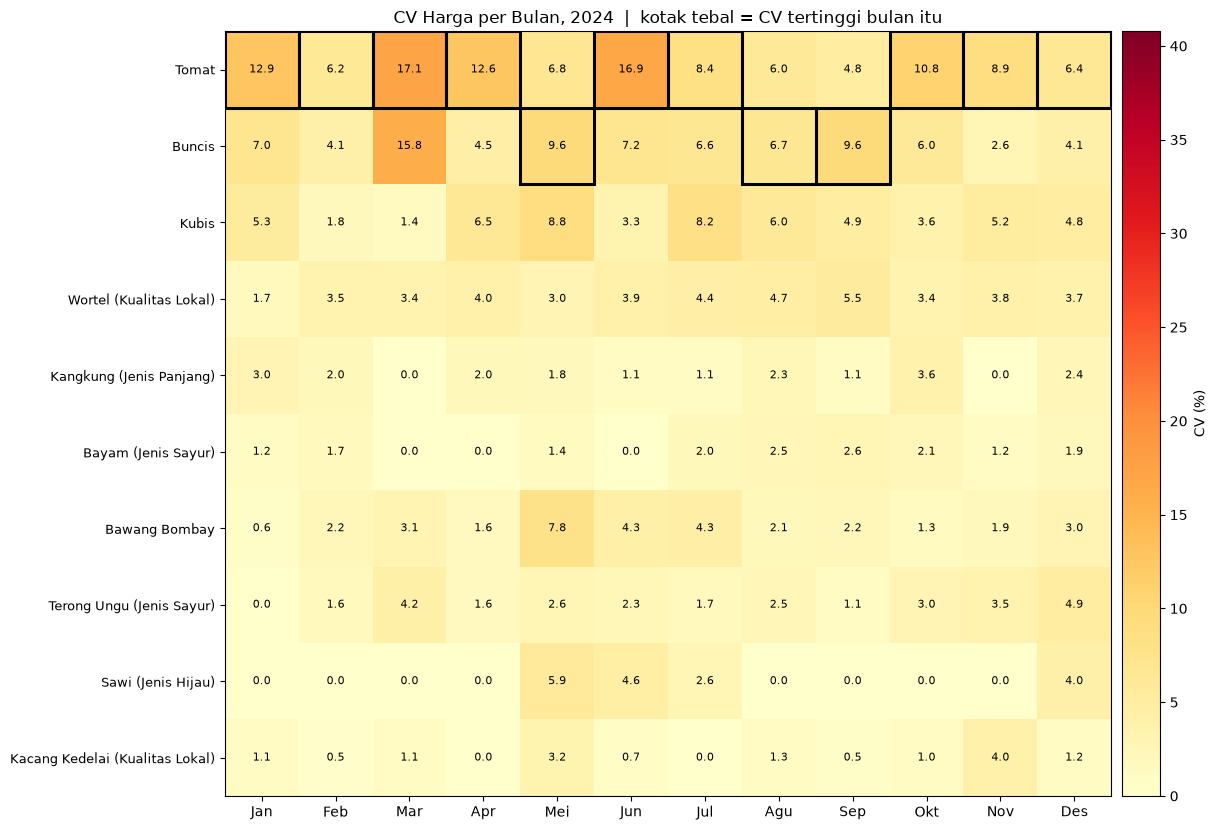

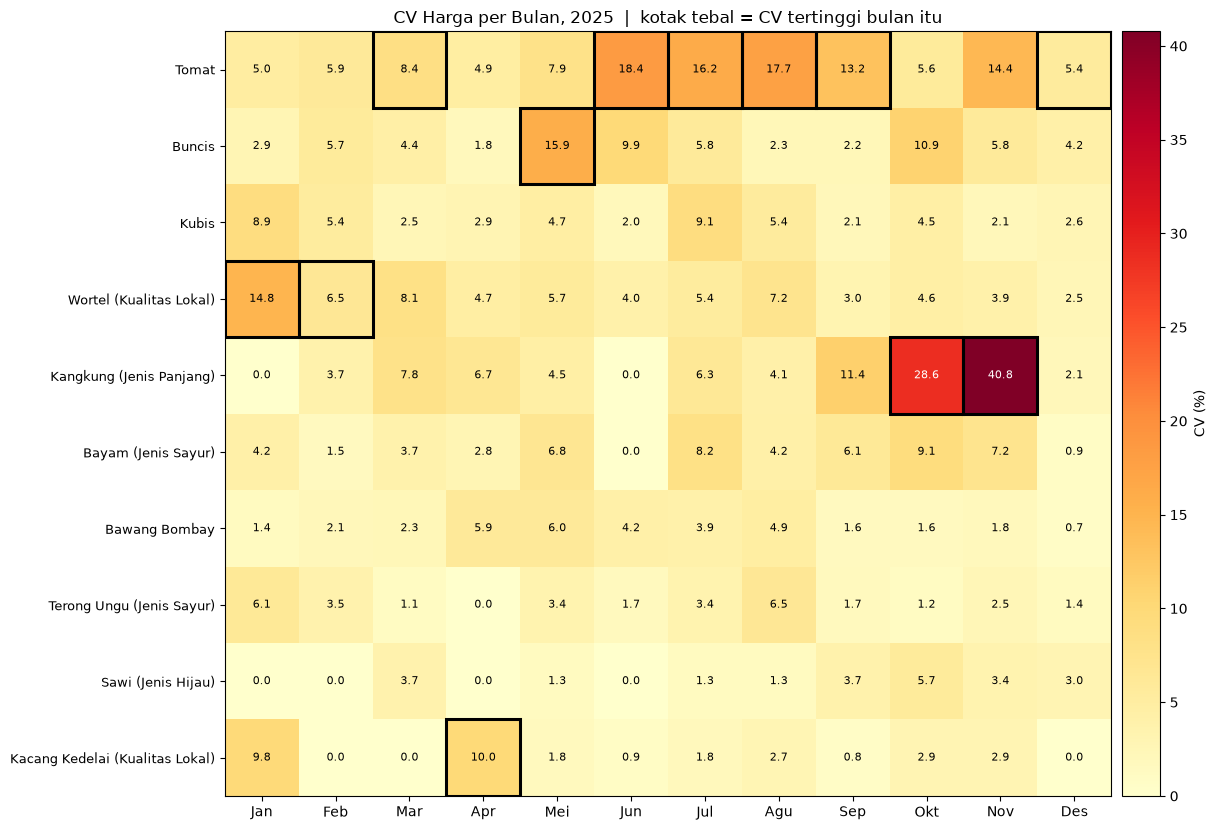

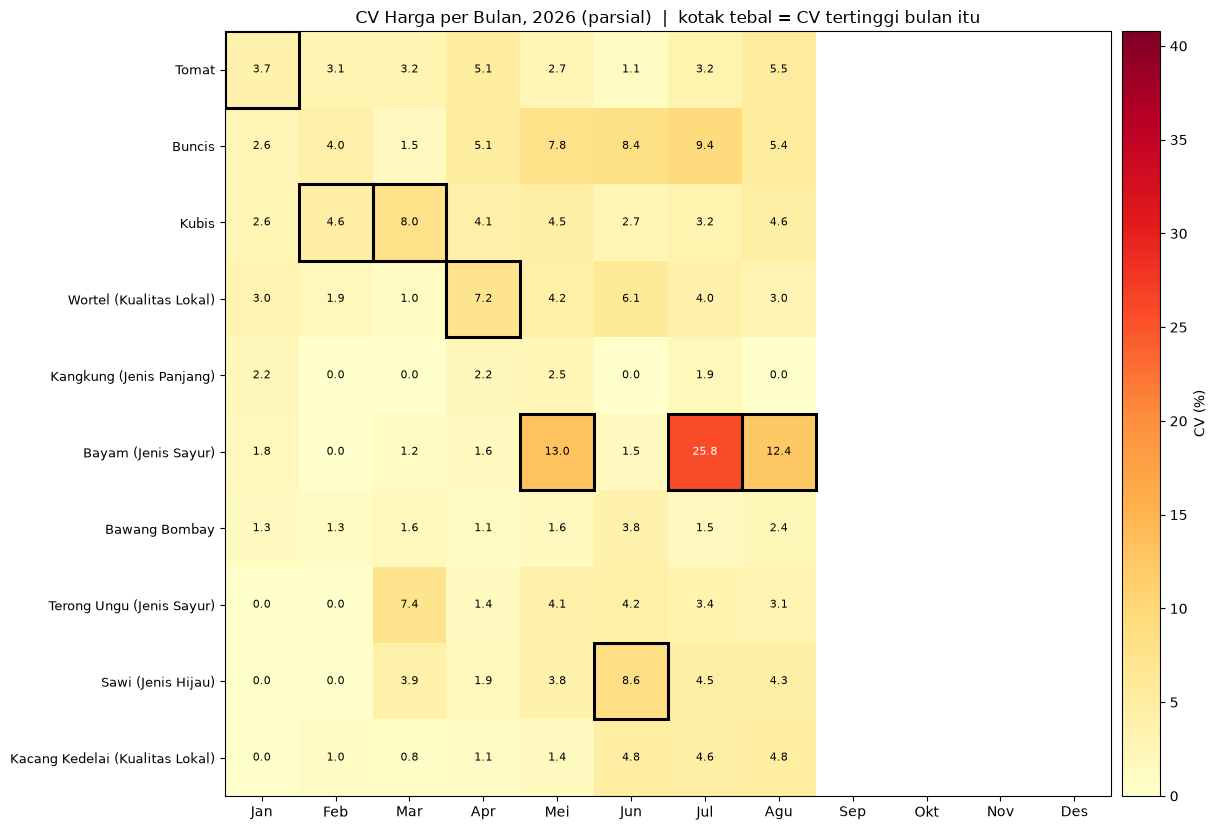

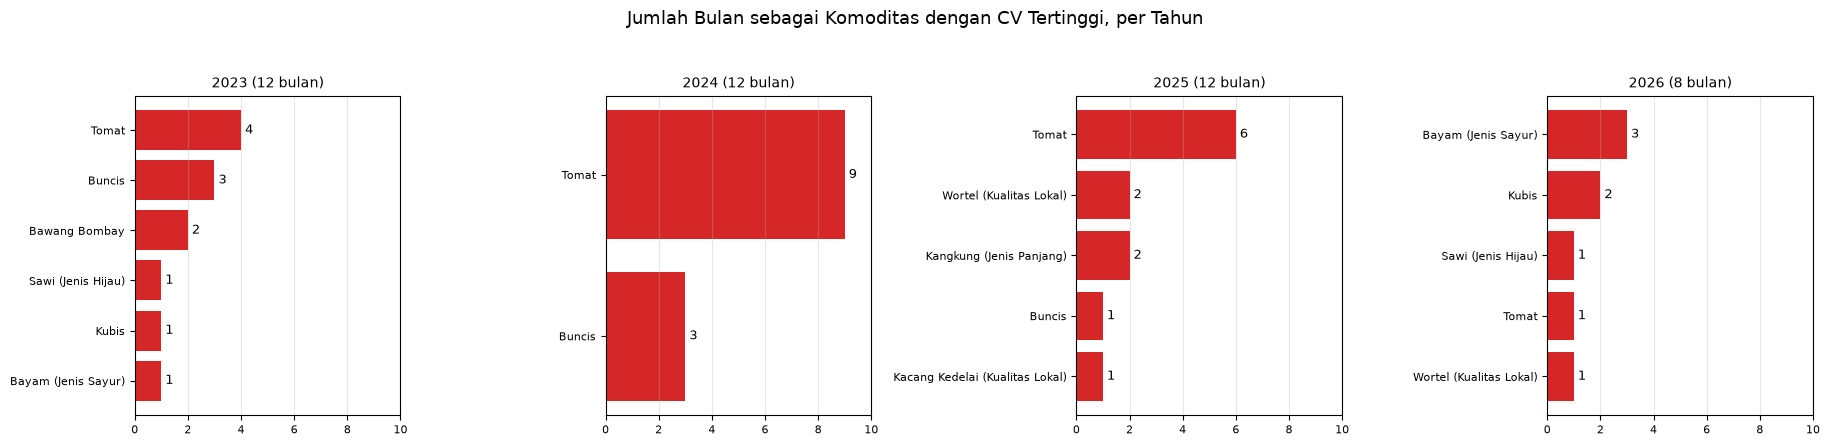

3 komoditas CV tertinggi per tahun:


,tahun,komoditas,cv_pct,tahun_parsial
0,2023,Tomat,27.14,False
1,2023,Bawang Bombay,21.53,False
2,2023,Buncis,12.80,False
3,2024,Tomat,43.40,False
4,2024,Buncis,15.60,False
5,2024,Kubis,14.73,False
6,2025,Tomat,32.02,False
7,2025,Kangkung (Jenis Panjang),21.17,False
8,2025,Wortel (Kualitas Lokal),14.24,False
9,2026,Bayam (Jenis Sayur),26.28,True


Komoditas dengan CV tertinggi tiap bulan:


nama_bulan,Jan,Feb,Mar,Apr,Mei,Jun,Jul,Agu,Sep,Okt,Nov,Des
tahun,,,,,,,,,,,,
2023,Bayam (Jenis Sayur),Kubis,Bawang Bombay,Bawang Bombay,Buncis,Tomat,Tomat,Buncis,Sawi (Jenis Hijau),Tomat,Buncis,Tomat
2024,Tomat,Tomat,Tomat,Tomat,Buncis,Tomat,Tomat,Buncis,Buncis,Tomat,Tomat,Tomat
2025,Wortel (Kualitas Lokal),Wortel (Kualitas Lokal),Tomat,Kacang Kedelai (Kualitas Lokal),Buncis,Tomat,Tomat,Tomat,Tomat,Kangkung (Jenis Panjang),Kangkung (Jenis Panjang),Tomat
2026,Tomat,Kubis,Kubis,Wortel (Kualitas Lokal),Bayam (Jenis Sayur),Sawi (Jenis Hijau),Bayam (Jenis Sayur),Bayam (Jenis Sayur),NaN,NaN,NaN,NaN


In [27]:
# ===== KOMODITAS DENGAN CV TERTINGGI: PER TAHUN DAN PER BULAN =====
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
Path("../reports/tables").mkdir(parents=True, exist_ok=True)
WARNA_TOP, WARNA_BIASA = "#d62728", "#9ecae1"

# ---------- 1. PER TAHUN: peringkat CV tiap tahun, 3 tertinggi diberi warna merah ----------
cv_tahun = statistik_tahunan.pivot(index="komoditas", columns="tahun", values="cv_pct")
parsial = set(statistik_tahunan.loc[statistik_tahunan["tahun_parsial"], "tahun"])
tahun_list = list(cv_tahun.columns)

fig, axes = plt.subplots(1, len(tahun_list), figsize=(4.6 * len(tahun_list), 4.8), sharex=True)
axes = np.atleast_1d(axes)
for ax, t in zip(axes, tahun_list):
    s = cv_tahun[t].dropna().sort_values()                       # terkecil di bawah, terbesar di atas
    warna = [WARNA_TOP if k >= len(s) - 3 else WARNA_BIASA for k in range(len(s))]
    ax.barh(s.index, s.values, color=warna)
    for y, v in enumerate(s.values):
        ax.text(v, y, f" {v:.1f}", va="center", fontsize=8)
    ax.set_title(f"{t} (parsial)" if t in parsial else str(t), fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(axis="x", alpha=0.3)
    ax.set_xlim(0, cv_tahun.max().max() * 1.15)
fig.suptitle("Komoditas dengan CV Harga Tertinggi per Tahun (merah = 3 tertinggi)", fontsize=13)
fig.supxlabel("CV (%)")
fig.tight_layout(rect=[0, 0.02, 1, 0.95])
fig.savefig("../reports/figures/cv_tertinggi_tahunan.png", dpi=150, bbox_inches="tight")
plt.show()

top_tahunan = (statistik_tahunan.sort_values(["tahun", "cv_pct"], ascending=[True, False])
               .groupby("tahun").head(3)[["tahun", "komoditas", "cv_pct", "tahun_parsial"]]
               .reset_index(drop=True))
top_tahunan.to_csv("../reports/tables/cv_tertinggi_tahunan.csv", index=False)

# ---------- 2. PER BULAN, DIPISAH PER TAHUN (Jan sampai Des) ----------
NAMA_BULAN = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
              7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}

sb = statistik_bulanan[statistik_bulanan["bulan_valid"]].copy()      # hanya bulan valid (>= 15 hari data)
sb["tahun"] = sb["bulan"].dt.year
sb["bulan_ke"] = sb["bulan"].dt.month

# Urutan baris dan skala warna dibuat sama di semua tahun supaya antar tahun bisa dibandingkan
urut_global = sb.groupby("komoditas")["cv_pct"].mean().sort_values(ascending=False).index
vmax = sb["cv_pct"].max()

top_rows = []
for t in sorted(sb["tahun"].unique()):
    cv = (sb[sb["tahun"] == t].pivot(index="komoditas", columns="bulan_ke", values="cv_pct")
          .reindex(index=urut_global, columns=range(1, 13)))
    top1 = {m: cv[m].idxmax() for m in cv.columns if cv[m].notna().any()}
    parsial_t = len(top1) < 12

    fig, ax = plt.subplots(figsize=(13, 0.62 * len(cv) + 2.2))
    im = ax.imshow(cv.values, cmap="YlOrRd", aspect="auto", vmin=0, vmax=vmax)
    for i in range(cv.shape[0]):
        for j in range(12):
            v = cv.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                        color="white" if v > 0.6 * vmax else "black")
    for m, nama in top1.items():                                   # kotak tebal = komoditas CV tertinggi bulan itu
        ax.add_patch(plt.Rectangle((m - 1.5, list(cv.index).index(nama) - 0.5), 1, 1,
                                   fill=False, edgecolor="black", linewidth=2.2))
        top_rows.append({"tahun": t, "bulan_ke": m, "nama_bulan": NAMA_BULAN[m],
                         "komoditas_cv_tertinggi": nama, "cv_pct": round(cv.at[nama, m], 2)})
    ax.set_xticks(range(12))
    ax.set_xticklabels([NAMA_BULAN[m] for m in range(1, 13)])
    ax.set_yticks(range(len(cv)))
    ax.set_yticklabels(cv.index, fontsize=9)
    fig.colorbar(im, ax=ax, label="CV (%)", pad=0.01)
    ax.set_title(f"CV Harga per Bulan, {t}" + (" (parsial)" if parsial_t else "")
                 + "  |  kotak tebal = CV tertinggi bulan itu", fontsize=12)
    fig.tight_layout()
    fig.savefig(f"../reports/figures/cv_bulanan_{t}.png", dpi=150, bbox_inches="tight")
    plt.show()

top_bulanan = pd.DataFrame(top_rows)
top_bulanan.to_csv("../reports/tables/cv_tertinggi_bulanan.csv", index=False)

# ---------- 3. Komoditas yang paling sering menjadi CV tertinggi, per tahun ----------
tahun_b = sorted(top_bulanan["tahun"].unique())
fig, axes = plt.subplots(1, len(tahun_b), figsize=(4.6 * len(tahun_b), 4.5), sharex=True)
axes = np.atleast_1d(axes)
for ax, t in zip(axes, tahun_b):
    d = top_bulanan[top_bulanan["tahun"] == t]
    f = d["komoditas_cv_tertinggi"].value_counts().sort_values()
    ax.barh(f.index, f.values, color=WARNA_TOP)
    for y, v in enumerate(f.values):
        ax.text(v, y, f" {v}", va="center", fontsize=9)
    ax.set_title(f"{t} ({len(d)} bulan)", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(axis="x", alpha=0.3)
    ax.set_xlim(0, top_bulanan.groupby("tahun")["komoditas_cv_tertinggi"].value_counts().max() + 1)
fig.suptitle("Jumlah Bulan sebagai Komoditas dengan CV Tertinggi, per Tahun", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig("../reports/figures/cv_bulanan_frekuensi_tertinggi.png", dpi=150, bbox_inches="tight")
plt.show()

print("3 komoditas CV tertinggi per tahun:")
display(top_tahunan)
print("Komoditas dengan CV tertinggi tiap bulan:")
(top_bulanan.pivot(index="tahun", columns="nama_bulan", values="komoditas_cv_tertinggi")
 .reindex(columns=list(NAMA_BULAN.values())))